# Decision Model: Wait or Ride On When a Citi Bike Station Is Full?

You ride up to your destination station to return a bike and every dock is taken. You can **wait** for someone to take a bike out (which frees a dock), or **ride on** to a nearby station and walk back. This notebook asks two questions:
1. Can a simple probability model built from 2024 trip records predict how soon a dock opens at a full station?
2. When real full-station moments are replayed, do decisions based on it beat simple rules?

`Final Notebook.ipynb` found that traffic at a station in a single 30-minute window is very noisy. This notebook works with the **rate** at which bikes leave a station instead, estimated from every comparable half-hour of the year.

| Step | Data | What it does |
|---|---|---|
| Train (Sections 2–4) | Trip records, days 1–21 of each month | Each station's departure rate by half-hour, day type, weather and season |
| Check 1 (Section 5) | Trip records, days 22–end | Are the predicted chances of at least one departure in the next *w* minutes right? |
| Check 2 (Sections 6–7) | Station status snapshots (every 2 min), days 22–end | At moments when a station was really full, how long until a dock opened? |
| Recalibrate (Section 8) | Status snapshots, days 15–21 | A small correction for what trip records can't see |
| Decide (Section 9) | Status snapshots, days 22–end | Replay real full-station moments under each decision rule |

Model parameters are fitted only on days 1–21; days 22–end are used for testing.

**Terms**
- **Departure rate (λ)**: expected bikes taken out of a station per unit of time. Each departure frees one dock.
- **Λ**: expected departures over a window. If departures arrive at random (a Poisson process), P(at least one in the window) = 1 − e^(−Λ).
- **Survival curve**: P(the station is still full *u* minutes after you arrive). The expected wait, capped at 60 minutes, is the area under it, summed in 2-minute steps to match the snapshots.
- **Calibrated**: events predicted at 30% happen about 30% of the time.
- **Brier score**: mean of (predicted probability − outcome)²; lower is better.

### Before running
1. Python 3.10+ with the packages in `requirements.txt` (see the README).
2. The 2024 trip CSVs in `data/trips/` (`TRIP_DATA_GLOB` in the config cell).
3. Section 6 downloads `citi_bike_stations_2024.parquet` (4.2 GB) from the public Kaggle dataset [rosenthal/citi-bike-stations](https://www.kaggle.com/datasets/rosenthal/citi-bike-stations) into `data/status/` if it isn't there, then builds a smaller cache (a few minutes, once).
4. Loading a full year of trips needs several GB of RAM.

Section 2 repeats `Final Notebook`'s cleaning steps so this notebook runs on its own.

## 1. Setup

In [1]:
import glob
import os
from datetime import datetime

import duckdb
import holidays
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from sklearn.linear_model import PoissonRegressor
from sklearn.neighbors import BallTree

In [2]:
# ---------------- Paths ----------------
TRIP_DATA_GLOB   = "data/trips/**/*.csv"                           # raw 2024 trip CSVs (same files Final Notebook uses)
STATUS_PATH      = "data/status/citi_bike_stations_2024.parquet"   # Kaggle: rosenthal/citi-bike-stations, 2024 file
STATUS_CACHE_DIR = "data/status/status_2024_cache"                  # small cache built from STATUS_PATH in Section 6
FIG_DIR          = "figures/decision_model"

# ---------------- Train / test split (by day of month, every month) ----------------
TRAIN_LAST_DAY  = 21   # days 1-21: trips used to fit the rate model
RECAL_FIRST_DAY = 15   # days 15-21: status snapshots used only for the recalibration and neighbor statistics (Sections 8-9)
TEST_FIRST_DAY  = 22   # days 22-end: held out; used only for testing
MONTHS          = list(range(1, 13))

# ---------------- Rate model ----------------
PRIOR_STRENGTH = 5     # how strongly sparse stations are pulled toward their overall daily pattern (in half-hour slots)
N_FIT_ROUNDS   = 3     # rounds of alternating between station patterns and the weather/season adjustment

# ---------------- Evaluation ----------------
STEP_MIN            = 2                 # status snapshots are 2 minutes apart, so time is measured in 2-minute steps
WINDOWS_MIN         = [2, 6, 10, 20]    # "will a dock open within w minutes?" is checked for these w
N_TRIP_QUERIES      = 300_000           # random (station, moment) checks for Section 5
PIT_HORIZON_MIN     = 120               # waiting-time check looks this far ahead
MAX_REPORT_AGE_MIN  = 10                # status reports older than this count as missing (Section 6)
N_EVENTS            = 240_000           # full-station moments sampled (Sections 7-8); every full snapshot has the same chance
N_REPLAY            = 60_000            # of those, how many are replayed through the decision rules (Section 9)

# ---------------- Decision model ----------------
NEIGHBOR_K        = 5      # consider up to K nearest other stations...
NEIGHBOR_RADIUS_M = 500    # ...but only within this straight-line distance (~6 short Manhattan blocks / 2 avenues)
DETOUR_FACTOR     = 1.3    # street distance is about 1.3x straight-line distance on a grid
BIKE_SPEED_M_MIN  = 200    # ~12 km/h riding
WALK_SPEED_M_MIN  = 80     # ~4.8 km/h walking
MAX_WAIT_MIN      = 60     # waits are counted up to 60 minutes (longer waits count as 60)
LONG_WAIT_MIN     = 15     # a total time above this counts as a "long" outcome in the Section 9 summary
NEIGHBOR_PRIOR_SNAPSHOTS = 30   # shrinkage for P(neighbor full | station full), in snapshots (30 = 1 hour)

SEED = 42
rng = np.random.default_rng(SEED)
os.makedirs(FIG_DIR, exist_ok=True)

N_STEPS   = MAX_WAIT_MIN // STEP_MIN    # number of 2-minute steps in the wait horizon
LAM_FLOOR = 1e-3                        # keeps log(expected departures) finite at stations with ~zero predicted demand

In [3]:
# Plot style: recessive axes/grid, one fixed color order for series
INK, INK_SECONDARY, GRID_COLOR = "#0b0b0b", "#52514e", "#e4e3df"
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # blue, orange, aqua, yellow (always in this order)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK_SECONDARY, "axes.labelcolor": INK, "axes.titleweight": "bold",
    "xtick.color": INK_SECONDARY, "ytick.color": INK_SECONDARY,
    "axes.grid": True, "grid.color": GRID_COLOR, "grid.linewidth": 0.8,
    "lines.linewidth": 2, "legend.frameon": False,
})

## 2. Preprocessing (same steps as `Final Notebook`)

Normalize ride ids, parse timestamps, drop rows without a station, keep rides recorded at both ends, then count departures (`df_exits_final`) and arrivals (`df_enter_final`) per station per 30 minutes. This notebook also keeps one location per station (to find neighbors) and the exact departure times (Section 5 checks predictions minute by minute).

In [4]:
#Loading raw data into the notebook (only the 7 columns used here, to save memory)
TRIP_COLUMNS = ['ride_id', 'started_at', 'ended_at', 'start_station_name', 'end_station_name', 'start_lat', 'start_lng']

csv_files = glob.glob(TRIP_DATA_GLOB, recursive=True)
dfs_2024 = [pd.read_csv(file, low_memory = False, usecols = TRIP_COLUMNS) for  file in csv_files]
df = pd.concat(dfs_2024, ignore_index= True)
del dfs_2024

In [5]:
#Ensuring all rides are of the same type

df['ride_id'] = df['ride_id'].astype(str).str.strip().str.lower()
df.head()

,ride_id,started_at,ended_at,start_station_name,end_station_name,start_lat,start_lng
0,c40e88bb937bdc15,2024-09-26 09:06:40.740,2024-09-26 09:27:55.009,Columbia St & Degraw St,6 Ave & Canal St,40.685930,-74.002424
1,f9db9fb8df1b9698,2024-09-15 16:36:01.749,2024-09-15 16:50:41.891,Kent Ave & Grand St,Pike St & E Broadway,40.716425,-73.965940
2,2c876366cd11d036,2024-09-24 22:44:19.582,2024-09-24 22:59:35.506,W 67 St & Broadway,Central Park North & Adam Clayton Powell Blvd,40.774925,-73.982666
3,d639068ac8d3de4d,2024-09-16 16:39:05.447,2024-09-16 17:02:05.830,Madison Ave & E 82 St,Central Park North & Adam Clayton Powell Blvd,40.778131,-73.960694
4,7c1b06cfc9849b71,2024-09-30 15:45:18.183,2024-09-30 15:46:42.613,Lafayette Ave & St James Pl,Willoughby Ave & Hall St,40.688515,-73.964763


In [6]:
#Checking for duplicate rides
assert not df['ride_id'].duplicated().any(), "duplicate ride ids"

In [7]:
#Creating Dataframes for enters and exits

df_exits = df[['ride_id', 'started_at', 'start_station_name']].copy()
df_enter = df[['ride_id', 'ended_at', 'end_station_name']].copy()

In [8]:
# One location per station: the median of its trip start coordinates (a few stations moved during the year)
station_coords = (
    df.groupby('start_station_name')[['start_lat', 'start_lng']]
    .median()
    .rename(columns={'start_lat': 'lat', 'start_lng': 'lon'})
)
print(f"{len(station_coords):,} stations with coordinates")

# Everything below works on df_exits / df_enter, so the full ride table can be freed
del df

2,273 stations with coordinates


In [9]:
#Fixing the dates in order to convert to datetime

exits_count = df_exits.shape[0]
enter_count = df_enter.shape[0]
print(f"before to datetime ride number for exits: {exits_count}" )
print(f"before to datetime ride number for arrival: {enter_count}" )

#STRIPPING THE TIMES TO CONVERT TO DATETIME

#Normalize & strip invisibles for exits
df_exits['started_at'] = (
    df_exits['started_at']
    .astype(str).str.strip()
    .str.replace('\u00A0', ' ', regex=False)
    .str.replace('\u200B', '',  regex=False)
)

#Crop anything past 19 chars
df_exits['started_at'] = df_exits['started_at'].str.replace(
    r'(^\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}).*$', 
    r'\1', 
    regex=True
)
df_enter['ended_at'] = (
    df_enter['ended_at']
    .astype(str).str.strip()
    .str.replace('\u00A0', ' ', regex=False)
    .str.replace('\u200B', '',  regex=False)
    .str.replace(
        r'(^\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}).*$', 
        r'\1', 
        regex=True
    )
)

#Parse with explicit format and convert dates to formal datetime index

df_exits['started_at'] = pd.to_datetime(
    df_exits['started_at'], 
    format='%Y-%m-%d %H:%M:%S', 
    errors='coerce'
)

df_enter['ended_at'] = pd.to_datetime(
    df_enter['ended_at'], 
    format='%Y-%m-%d %H:%M:%S', 
    errors='coerce'
)

print(f"after strip and datetime exits: {df_exits.shape[0]}")
print(f"after strip and datetime enter: {df_enter.shape[0]}")

#Verify that there aren't any NAT
print("Failed exits:", df_exits['started_at'].isna().sum())
print("Failed enters:", df_enter['ended_at'].isna().sum())

before to datetime ride number for exits: 44303209
before to datetime ride number for arrival: 44303209


after strip and datetime exits: 44303209
after strip and datetime enter: 44303209
Failed exits: 0
Failed enters: 0


In [10]:
# DROPS NAT IF IT EXISTS AND SETS DATETIME INDEX
df_exits = df_exits.dropna(subset=['started_at'])
df_enter = df_enter.dropna(subset=['ended_at'])

df_exits = df_exits.set_index('started_at')
df_enter = df_enter.set_index('ended_at')

In [11]:
#Printing and dropping NAN values in both departure and arrival dataframes

print(f"count for NAN values in start station names: {df_exits['start_station_name'].isna().sum()}")
print(f"count for NAN values in end station names: {df_enter['end_station_name'].isna().sum()}")

df_exits = df_exits.dropna(subset='start_station_name')
df_enter = df_enter.dropna(subset='end_station_name')

count for NAN values in start station names: 29835
count for NAN values in end station names: 114545


In [12]:
# DROP ANY RIDES THAT AREN'T PRESENT IN BOTH DATAFRAMES

df_exits = df_exits[df_exits['ride_id'].isin(df_enter['ride_id'])]
df_enter = df_enter[df_enter['ride_id'].isin(df_exits['ride_id'])]

print(df_exits.shape[0])
print(df_enter.shape[0])

44173378
44173378


In [13]:
# Keep the exact (un-binned) departure times. The next cell bins departures into 30-minute counts,
# but Section 5 checks "was there a departure within w minutes of this moment?", which needs exact times.
departure_times = df_exits['start_station_name'].copy()        # index = started_at, value = station name
departure_times = departure_times[departure_times.index.year == 2024]
print(f"{len(departure_times):,} departures in 2024")

44,173,014 departures in 2024


In [14]:
#Grouping data by stations to show number of rides per station at each time

print(f"number of rows without station name exits: {df_exits['start_station_name'].isna().sum()}")
print(f"number of rows without station name enter: {df_enter['end_station_name'].isna().sum()}")

df_exits = df_exits.groupby('start_station_name').resample('30min')['ride_id'].count()
df_enter = df_enter.groupby('end_station_name').resample('30min')['ride_id'].count()


print(f"after resampling and grouping by stations exits: {df_exits.shape[0]}")
print(f"after resampling and grouping by stations enter: {df_enter.shape[0]}")

number of rows without station name exits: 0
number of rows without station name enter: 0


after resampling and grouping by stations exits: 37558550
after resampling and grouping by stations enter: 38437665


In [15]:
#Unstacking dataframe making stations as columns so it is easier to analyze

df_exits_final = df_exits.unstack(level='start_station_name', fill_value=0)
print(df_exits_final.shape)

(17589, 2273)


In [16]:
#Unstacking dataframe making stations as columns so it is easier to analyze

df_enter_final = df_enter.unstack(level='end_station_name', fill_value=0)
print(df_enter_final.shape)

(17568, 2290)


In [17]:
# The 30-minute counts are now in df_exits_final / df_enter_final; free the per-ride series
del df_exits, df_enter

### Weather
Hourly Central Park weather from Meteostat. Meteostat timestamps are UTC and trip times are New York local time, so the weather is converted to New York time before it's resampled to 30 minutes.

In [18]:
#Importing weather features
from meteostat import Hourly, Point

# Central Park coordinates
cp = Point(40.7812, -73.9665)

start = datetime(2024, 1, 1, 0)
end   = datetime(2025, 1, 1, 6)   # 6 extra hours so Dec 31 evening is still covered after the time-zone conversion below

# Fetch hourly data
weather_df = Hourly(cp, start, end).fetch()
# Meteostat timestamps are UTC; trip timestamps are New York local time. Convert so weather lines up with rides.
weather_df.index = weather_df.index.tz_localize("UTC").tz_convert("America/New_York").tz_localize(None)
weather_df = weather_df[~weather_df.index.duplicated(keep="first")]   # clocks fall back once a year and repeat 1am
weather_df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8790 entries, 2023-12-31 19:00:00 to 2025-01-01 01:00:00
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   temp    8790 non-null   Float64
 1   dwpt    8790 non-null   Float64
 2   rhum    8790 non-null   Float64
 3   prcp    8784 non-null   Float64
 4   snow    0 non-null      Float64
 5   wdir    8790 non-null   Float64
 6   wspd    8790 non-null   Float64
 7   wpgt    0 non-null      Float64
 8   pres    8790 non-null   Float64
 9   tsun    0 non-null      Float64
 10  coco    8784 non-null   Float64
dtypes: Float64(11)
memory usage: 918.5 KB


In [19]:
# Rename and slice columns while keeping temp, precipitation, and wind speed. Also creates boolean column to check if raining

weather_df = (
    weather_df.rename(columns={
        "temp": "temp_c",        # °C
        "prcp": "precip_mm",     # mm
        "wspd": "wind_speed",      # km/h
    })[["temp_c", "precip_mm", "wind_speed"]].copy()
)

precip_col = weather_df.precip_mm.resample('30min').ffill() / 2

temp_col = weather_df.temp_c.resample('30min').interpolate('time')

wind_col = weather_df.wind_speed.resample('30min').ffill()

weather_df = pd.concat([precip_col, temp_col, wind_col], axis=1)

weather_df["is_raining"] = (weather_df["precip_mm"].fillna(0) > 0).astype(int)

weather_df = weather_df.loc["2024-01-01":"2024-12-31 23:30"]

weather_df['temp_f'] = weather_df['temp_c'] * 9/5 + 32

weather_df.drop('temp_c', axis=1, inplace=True)

# Number of 30-minute rows (should be 17,568 = 366 days x 48)
print(weather_df.shape[0])

17568


### Calendar features (reused)
Three similarly named objects come out of these cells:
- `dates`: every half-hour of 2024 (17,568 timestamps);
- `dates_df`: True/False for each of those half-hours, True on US holidays;
- `days_dates_df`: weekend flag, day of week and month for each half-hour.

In [20]:
#Creating 'dates' column that represents US National Holidays 

dates = pd.date_range('2024-01-01 00:00', '2024-12-31 23:30', freq="30min")
dates_df = dates.to_series().dt.date.isin(holidays.US(years=2024))
dates_df.shape[0]

17568

In [21]:
#Adding is_weekend column to show if day is weekend or not

is_weekend_col = pd.Series(dates.dayofweek >= 5, index=dates, name= 'is_weekend')
day_col = pd.Series(dates.dayofweek, index=dates, name='day of week')
month_col = pd.Series(dates.month, index=dates, name='month')
print(is_weekend_col.shape[0])
print(day_col.shape[0])
print(month_col.shape[0])

17568
17568
17568


In [22]:
# #Adding Day of Week and Month 

days_dates_df = pd.concat([is_weekend_col, day_col, month_col], axis=1)
print(f"days and dates len: {days_dates_df.shape[0]}")
print(f"weather len: {weather_df.shape[0]}")
print(f"holidays len: {dates_df.shape[0]}")

days and dates len: 17568
weather len: 17568
holidays len: 17568


In [23]:
dates_df.name = 'holidays'

## 3. Arrange the data for modeling

From here on, the model works on plain arrays:

| Name | Shape | Meaning |
|---|---|---|
| `Y` | slots × stations | departures in each 30-minute slot of 2024 (17,568 slots) |
| `active` | slots × stations | True in months where the station had at least one departure on that month's training days |
| `profile_key` | slots | which of 96 calendar profiles a slot belongs to: 48 half-hours × {workday, weekend/holiday} |
| `is_train`, `is_test` | slots | day of month ≤ 21, or ≥ 22 |
| `X` | slots × features | weather and season for each slot |
| `dep_key` | departures | every exact departure time, sorted by station then time (for fast lookups) |

Times are measured as **minutes since 2024-01-01 00:00 New York time** throughout.

In [24]:
# Departures per station per 30-minute slot, for every slot of 2024 (slots with no rides = 0)
departures = df_exits_final[df_exits_final.index.year == 2024].reindex(dates, fill_value=0)

stations = departures.columns.to_numpy()                  # station names; a station's position here is its index everywhere below
station_idx = {name: i for i, name in enumerate(stations)}
Y = departures.to_numpy(dtype=np.float32)                 # shape (n_slots, n_stations)
n_slots, n_stations = Y.shape

# Train / test split by day of month
is_train = np.asarray(dates.day <= TRAIN_LAST_DAY)
is_test = np.asarray(dates.day >= TEST_FIRST_DAY)

# A station counts as existing in a month if it had at least one departure on that month's TRAINING days.
# So a station that opened in June isn't treated as having zero demand in January, and nothing about
# the test days is used to decide which stations exist.
month_of_slot = np.asarray(dates.month) - 1
exists_in_month = np.stack([(Y[is_train & (month_of_slot == m)] > 0).any(axis=0) for m in range(12)])   # (12, n_stations)
active = exists_in_month[month_of_slot]                                                                # (n_slots, n_stations)

# Calendar profile of each slot: 48 half-hours x {workday, weekend/holiday} = 96 profiles
slot_of_day = np.asarray(dates.hour * 2 + dates.minute // 30)
is_offday = (days_dates_df['is_weekend'] | dates_df).to_numpy()
profile_key = is_offday.astype(int) * 48 + slot_of_day

print(f"{n_stations:,} stations x {n_slots:,} half-hour slots")
print(f"train slots: {is_train.sum():,}   test slots: {is_test.sum():,}")
print(f"departures in train: {Y[is_train].sum():,.0f}   in test: {Y[is_test].sum():,.0f}")

2,273 stations x 17,568 half-hour slots
train slots: 12,096   test slots: 5,472
departures in train: 30,845,536   in test: 13,327,479


In [25]:
# Exact departure times, packed as (station index x KEY_SCALE + minute) and sorted.
# Because KEY_SCALE is larger than the number of minutes in a year, sorting this one number sorts by
# station first and then by time, so "departures at station s between t1 and t2" is two binary searches.
YEAR_START = pd.Timestamp("2024-01-01")
KEY_SCALE = 1_000_000

dep_station = pd.Categorical(departure_times.to_numpy(), categories=stations).codes.astype(np.int64)
assert (dep_station >= 0).all(), "every departure should belong to a known station"
dep_min = ((departure_times.index - YEAR_START) / pd.Timedelta(minutes=1)).to_numpy()
dep_key = np.sort(dep_station * KEY_SCALE + dep_min)
del departure_times, dep_station, dep_min
print(f"{len(dep_key):,} exact departure times indexed")

44,173,014 exact departure times indexed


In [26]:
# Weather + season features for every slot. Each feature acts as a multiplier on all stations' departure rates.
TEMP_BINS = [-np.inf, 35, 45, 55, 65, 75, 85, np.inf]
TEMP_LABELS = ["<35F", "35-45F", "45-55F", "55-65F", "65-75F", "75-85F", ">85F"]
N_SEASON_WAVES = 3      # sine/cosine pairs for the seasonal curve (1 = one bump per year; more = more flexible)

# Smooth seasonal curve: sine/cosine waves of the time of year. Captures what weather alone doesn't
# (daylight, tourism, school calendar), and changes smoothly across the held-out days 22-end of each month.
year_fraction = (np.asarray(dates.day_of_year) - 1 + np.asarray(dates.hour) / 24) / 366
season_features = pd.DataFrame(
    {f"season_{fn.__name__}{k}": fn(2 * np.pi * k * year_fraction) for k in range(1, N_SEASON_WAVES + 1) for fn in (np.sin, np.cos)},
    index=dates,
)

w = weather_df.reindex(dates).ffill().bfill()
weather_features = pd.concat([
    w["is_raining"].rename("raining"),
    # capped at 10 mm per half hour (rare) so a few storms don't dominate the fit
    np.log1p(w["precip_mm"].fillna(0).clip(upper=10)).rename("log_precip_mm"),
    (w["wind_speed"] / 10).rename("wind_per_10kmh"),
    # temperature in bins, compared against a comfortable 65-75F
    pd.get_dummies(pd.cut(w["temp_f"], TEMP_BINS, labels=TEMP_LABELS), prefix="temp").drop(columns="temp_65-75F"),
    season_features,
], axis=1).astype(float)
X = weather_features.to_numpy()
weather_features.head()

,raining,log_precip_mm,wind_per_10kmh,temp_<35F,temp_35-45F,temp_45-55F,temp_55-65F,temp_75-85F,temp_>85F,season_sin1,season_cos1,season_sin2,season_cos2,season_sin3,season_cos3
2024-01-01 00:00:00,1.0,0.04879,1.10,0.0,1.0,0.0,0.0,0.0,0.0,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000
2024-01-01 00:30:00,1.0,0.04879,1.10,0.0,1.0,0.0,0.0,0.0,0.0,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000
2024-01-01 01:00:00,0.0,0.00000,0.70,0.0,1.0,0.0,0.0,0.0,0.0,0.000715,1.000000,0.001431,0.999999,0.002146,0.999998
2024-01-01 01:30:00,0.0,0.00000,0.70,0.0,1.0,0.0,0.0,0.0,0.0,0.000715,1.000000,0.001431,0.999999,0.002146,0.999998
2024-01-01 02:00:00,0.0,0.00000,0.68,0.0,1.0,0.0,0.0,0.0,0.0,0.001431,0.999999,0.002861,0.999996,0.004292,0.999991


## 4. The rate model (trained on trips only)

For station $s$ in 30-minute slot $t$, expected departures are

$$\lambda_{s,t} = \text{base}_s(\text{profile}_t) \times m_t$$

- **base**: the station's average departures for that half-hour and day type (workday or weekend/holiday). Stations with little data are pulled toward their own overall level, shaped like the system-wide daily pattern (`PRIOR_STRENGTH`).
- **$m_t$**: one multiplier per slot, shared by all stations, from a **Poisson regression** on rain, precipitation, wind, temperature band and a smooth seasonal curve (sine/cosine waves of the time of year, which continue smoothly into the held-out days 22–end).

Within a slot, departures are assumed to arrive at a steady rate, so the model can answer questions about windows of any length.

Because $m_t$ is shared, the regression only needs total observed vs. total expected departures per half-hour (one row per slot instead of one per station-slot). The base and the multiplier depend on each other, so they're fitted in turn for `N_FIT_ROUNDS` rounds; the printed change should shrink toward 0.

In [27]:
def fit_base_rates(Y, active, use_slot, profile_key, multiplier, prior_strength=PRIOR_STRENGTH):
    """Each station's expected departures per 30-min slot, for each of the 96 calendar profiles,
    after dividing out the weather/season multiplier. Shape (96, n_stations).

    Sparse station-profiles are shrunk toward prior = station's overall average x system-wide profile shape,
    as if `prior_strength` extra slots had been observed at the prior rate."""
    n_keys = 96
    observed = np.zeros((n_keys, Y.shape[1]))
    exposure = np.zeros((n_keys, Y.shape[1]))     # number of slots observed, weighted by the multiplier
    for k in range(n_keys):
        rows = np.flatnonzero(use_slot & (profile_key == k))
        is_open = active[rows]
        observed[k] = (Y[rows] * is_open).sum(axis=0)
        exposure[k] = (multiplier[rows, None] * is_open).sum(axis=0)

    station_total = exposure.sum(axis=0)
    station_rate = np.divide(observed.sum(axis=0), station_total, out=np.zeros(Y.shape[1]), where=station_total > 0)
    expected_by_profile = (exposure * station_rate).sum(axis=1)
    profile_shape = np.divide(observed.sum(axis=1), expected_by_profile, out=np.ones(n_keys), where=expected_by_profile > 0)
    prior = profile_shape[:, None] * station_rate[None, :]

    return ((observed + prior_strength * prior) / (exposure + prior_strength)).astype(np.float32)


def fit_weather_multiplier(Y, active, use_slot, profile_key, base, X):
    """Poisson regression of total observed departures per slot on weather/season features,
    with the base model's total expected departures as the exposure.
    (Fitting observed/expected with weight = expected is the standard way to fit an exposure offset in sklearn.)"""
    expected_total = (base[profile_key] * active).sum(axis=1)
    observed_total = (Y * active).sum(axis=1)
    rows = use_slot & (expected_total > 0)
    model = PoissonRegressor(alpha=1e-4, solver="newton-cholesky", max_iter=300)
    model.fit(X[rows], observed_total[rows] / expected_total[rows], sample_weight=expected_total[rows])
    return model

In [28]:
multiplier = np.ones(n_slots)
for round_number in range(1, N_FIT_ROUNDS + 1):
    base = fit_base_rates(Y, active, is_train, profile_key, multiplier)
    if round_number == 1:
        base_time_only = base.copy()      # time-of-day-only model (no weather), kept for comparison in Section 5
    weather_model = fit_weather_multiplier(Y, active, is_train, profile_key, base, X)
    new_multiplier = weather_model.predict(X)
    print(f"round {round_number}: largest change in the weather/season multiplier = {np.abs(new_multiplier - multiplier).max():.3f}")
    multiplier = new_multiplier

base = fit_base_rates(Y, active, is_train, profile_key, multiplier)   # final station patterns given the final multiplier

round 1: largest change in the weather/season multiplier = 0.793


round 2: largest change in the weather/season multiplier = 0.053


round 3: largest change in the weather/season multiplier = 0.011


**Weather effects.** Each number multiplies every station's expected departures, relative to an otherwise identical half-hour that is dry, 65–75°F and windless (1.00 = no difference). They're associations in observational data, estimated jointly with time of day and season. `raining` is the step from dry to any rain; `log_precip_mm` adds to it per unit of log(1 + mm per half hour). The seasonal terms are shown as a curve below.

In [29]:
coefficients = pd.Series(weather_model.coef_, index=weather_features.columns)
weather_terms = [name for name in coefficients.index if not name.startswith("season_")]
effects = np.exp(coefficients[weather_terms]).rename("multiplies departures by").round(2).to_frame()
effects

,multiplies departures by
raining,0.78
log_precip_mm,0.67
wind_per_10kmh,0.98
temp_<35F,0.55
temp_35-45F,0.67
temp_45-55F,0.77
temp_55-65F,0.90
temp_75-85F,1.09
temp_>85F,1.04


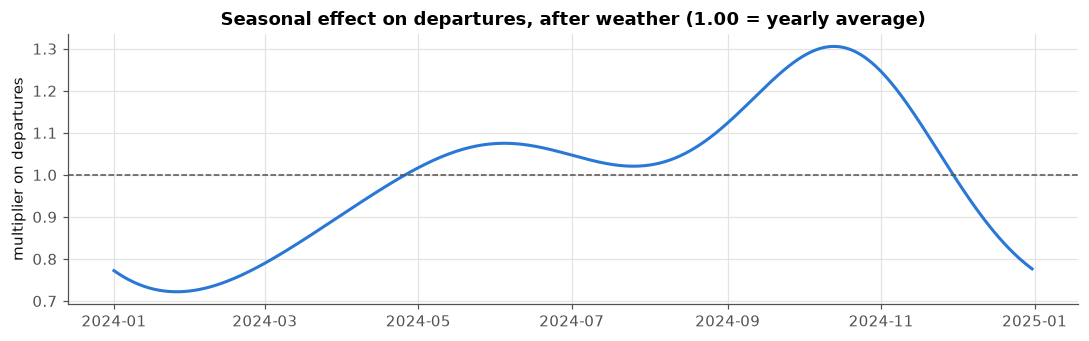

In [30]:
# The fitted seasonal curve: how much busier or quieter the system is at each point of the year (1.00 = yearly average),
# after accounting for weather. Training days are days 1-21 of each month; the curve fills in days 22-end smoothly.
season_terms = [name for name in coefficients.index if name.startswith("season_")]
seasonal_multiplier = np.exp(season_features[season_terms].to_numpy() @ coefficients[season_terms].to_numpy())
seasonal_multiplier = pd.Series(seasonal_multiplier / seasonal_multiplier.mean(), index=dates).resample("D").mean()

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(seasonal_multiplier.index, seasonal_multiplier.to_numpy(), color=SERIES_COLORS[0])
ax.axhline(1, linestyle="--", color=INK_SECONDARY, linewidth=1)
ax.set_ylabel("multiplier on departures")
ax.set_title("Seasonal effect on departures, after weather (1.00 = yearly average)")
plt.tight_layout()
plt.show()

In [31]:
# Expected departures in every 30-min slot (rows) at every station (columns), and their running totals.
lam_slot = base[profile_key] * multiplier[:, None].astype(np.float32) * active
lam_time_only = base_time_only[profile_key] * active      # time-of-day-only model, for the comparison in Section 5


def running_total(lam):
    """cum[i, s] = expected departures at station s before slot i."""
    cum = np.zeros((n_slots + 1, n_stations))
    np.cumsum(lam, axis=0, dtype=np.float64, out=cum[1:])
    return cum


cum_expected = running_total(lam_slot)
cum_time_only = running_total(lam_time_only)


def _expected_since_year_start(station, t_min, lam, cum):
    """Expected departures at `station` from 2024-01-01 00:00 up to t_min (rate is constant within each half hour)."""
    t_min = np.clip(t_min, 0, n_slots * 30 - 1e-6)
    slot = (t_min // 30).astype(np.int64)
    return cum[slot, station] + (t_min - 30 * slot) / 30 * lam[slot, station]


def expected_departures(station, start_min, duration_min, lam=None, cum=None):
    """Λ: expected number of departures at `station` between start_min and start_min + duration_min.
    Uses the full model unless another (lam, cum) pair is given. Accepts numpy arrays (they broadcast).
    Times are minutes since 2024-01-01 00:00 New York time."""
    if lam is None:
        lam, cum = lam_slot, cum_expected
    station = np.asarray(station)
    start_min = np.asarray(start_min, dtype=float)
    return (_expected_since_year_start(station, start_min + duration_min, lam, cum)
            - _expected_since_year_start(station, start_min, lam, cum))


def survival_curves(station, t_min, elapsed_min=0.0, recal=None):
    """Probability a full station is STILL full u minutes after t_min, for u = 0, 2, 4, ..., MAX_WAIT_MIN.
    Returns shape (n, N_STEPS + 1); column k is u = 2k minutes.

    recal=None    -> trip-based model: a dock opens with every departure, so P(still full) = exp(-Λ).
    recal=(a,b,c) -> recalibrated model from Section 8; elapsed_min = how long the station has already been full
                     (it has no effect when c = 0)."""
    station = np.asarray(station)[:, None]
    steps = np.arange(N_STEPS)[None, :]
    step_start = np.asarray(t_min, dtype=float)[:, None] + STEP_MIN * steps
    hazard = expected_departures(station, step_start, STEP_MIN)          # expected dock openings in each 2-min step
    if recal is not None:
        a, b, c = recal
        elapsed = np.asarray(elapsed_min, dtype=float).reshape(-1, 1) + STEP_MIN * steps
        hazard = np.exp(a + b * np.log(hazard + LAM_FLOOR) + c * np.log1p(elapsed))
    cumulative = np.concatenate([np.zeros((hazard.shape[0], 1)), np.cumsum(hazard, axis=1)], axis=1)
    return np.exp(-cumulative)


def expected_wait(survival):
    """Expected minutes until a dock shows as open, counting at most MAX_WAIT_MIN: the area under the survival curve
    in 2-minute steps. Docks are only seen at snapshots, so the wait is 2k minutes when the first open snapshot is k steps
    after arrival, and its expectation is 2 x (sum of the chances of still being full at steps 0, 1, ..., N_STEPS - 1)."""
    return STEP_MIN * survival[:, :N_STEPS].sum(axis=1)

**Sanity check.** Model vs. actual departures at the busiest station during one held-out week. Single half-hours are noisy, so the dots scatter around the line; the checks below test the probabilities.

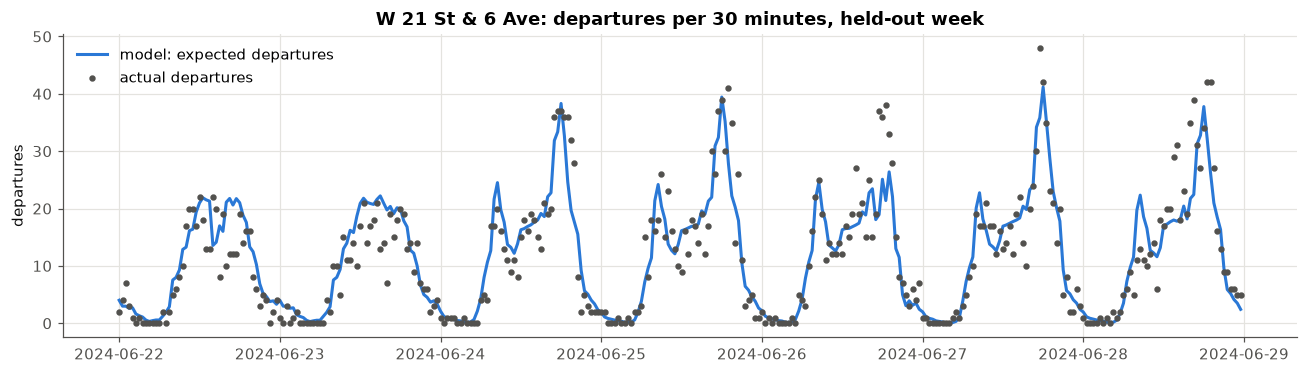

In [32]:
busiest = int(np.argmax(Y[is_train].sum(axis=0)))
week = np.flatnonzero((dates >= "2024-06-22") & (dates < "2024-06-29"))

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(dates[week], lam_slot[week, busiest], color=SERIES_COLORS[0], label="model: expected departures")
ax.scatter(dates[week], Y[week, busiest], s=10, color=INK_SECONDARY, label="actual departures", zorder=3)
ax.set_title(f"{stations[busiest]}: departures per 30 minutes, held-out week")
ax.set_ylabel("departures")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 5. Check 1: held-out trip records

300,000 random (station, moment, window) queries from the test days, with windows of 2, 6, 10 or 20 minutes. The prediction is P(at least one departure) $= 1 - e^{-\Lambda}$; the outcome is looked up in the exact departure times. Queries start early enough that every look-ahead stays inside the same month's test days. Three models are compared:
1. **Station average**: one constant rate per station.
2. **Time of day**: the station's half-hour pattern, without weather or season.
3. **Time of day + weather/season**: the full model.

These moments are random, not moments when the station was full, and some fall when a station was empty (no one can take a bike out). Section 7 tests at real full stations.

In [33]:
def count_departures(station, start_min, end_min):
    """Number of actual departures at `station` in the window (start_min, end_min]."""
    lo = np.searchsorted(dep_key, station * KEY_SCALE + start_min, side="right")
    hi = np.searchsorted(dep_key, station * KEY_SCALE + end_min, side="right")
    return hi - lo


def minutes_to_next_departure(station, t_min, horizon):
    """Minutes from t_min until the next actual departure at `station`; NaN if none within `horizon`."""
    idx = np.searchsorted(dep_key, station * KEY_SCALE + t_min, side="right")
    next_time = dep_key[np.minimum(idx, len(dep_key) - 1)] - station * KEY_SCALE
    gap = next_time - t_min
    return np.where((gap > 0) & (gap <= horizon), gap, np.nan)


def brier(p, y):
    return np.mean((p - y) ** 2)


def log_loss(p, y):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))


def reliability_table(p, y, n_bins=10, min_count=50):
    """Group predictions into bins (0-10%, 10-20%, ...) and compare average prediction with how often it happened."""
    bins = np.minimum((p * n_bins).astype(int), n_bins - 1)
    table = (pd.DataFrame({"bin": bins, "predicted": p, "observed": y})
             .groupby("bin").agg(predicted=("predicted", "mean"), observed=("observed", "mean"), n=("observed", "size")))
    return table[table.n >= min_count]


def plot_reliability(ax, curves, title):
    """curves: list of (label, predicted, observed). Points on the dashed diagonal = perfectly calibrated."""
    ax.plot([0, 1], [0, 1], linestyle="--", color=INK_SECONDARY, linewidth=1)
    for color, (label, p, y) in zip(SERIES_COLORS, curves):
        table = reliability_table(p, y)
        ax.plot(table.predicted, table.observed, marker="o", markersize=6, color=color, label=label)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel("predicted probability"); ax.set_ylabel("observed frequency")
    ax.set_title(title)
    ax.legend(loc="upper left")

In [34]:
# Random (station, moment, window) queries from the test days, at stations that existed at the time. Queries start early
# enough that the longest look-ahead (PIT_HORIZON_MIN, used below) ends inside the same month's test days.
month_end_min = np.asarray(((dates.to_period("M") + 1).to_timestamp() - YEAR_START) / pd.Timedelta(minutes=1))
query_slot_ok = is_test & (np.arange(n_slots) * 30 + 30 + PIT_HORIZON_MIN <= month_end_min)
test_cells = np.flatnonzero((active & query_slot_ok[:, None]).ravel())
pick = rng.choice(test_cells, size=min(N_TRIP_QUERIES, len(test_cells)), replace=False)
q_slot, q_station = np.unravel_index(pick, active.shape)
q_t = q_slot * 30 + rng.uniform(0, 30, size=len(pick))
q_w = rng.choice(WINDOWS_MIN, size=len(pick))
q_observed = (count_departures(q_station, q_t, q_t + q_w) > 0).astype(float)

# Model 1: one constant rate per station (departures per minute during training)
train_minutes = (active & is_train[:, None]).sum(axis=0) * 30
station_avg_per_min = np.divide(Y[is_train].sum(axis=0), train_minutes, out=np.zeros(n_stations), where=train_minutes > 0)

trip_predictions = {
    "1. Station average": 1 - np.exp(-station_avg_per_min[q_station] * q_w),
    "2. Time of day": 1 - np.exp(-expected_departures(q_station, q_t, q_w, lam_time_only, cum_time_only)),
    "3. Time of day + weather/season": 1 - np.exp(-expected_departures(q_station, q_t, q_w)),
}
del lam_time_only, cum_time_only   # only needed for the comparison above

rows = []
for name, p in trip_predictions.items():
    for w_min in WINDOWS_MIN:
        m = q_w == w_min
        rows.append({"model": name, "window (min)": w_min, "Brier": brier(p[m], q_observed[m]),
                     "log loss": log_loss(p[m], q_observed[m]),
                     "avg predicted": p[m].mean(), "actually happened": q_observed[m].mean()})
trip_scores = pd.DataFrame(rows)
print("Brier score (lower is better):")
trip_scores.pivot(index="model", columns="window (min)", values="Brier").round(4)

Brier score (lower is better):


window (min),2,6,10,20
model,,,,
1. Station average,0.0540,0.1113,0.1440,0.1878
2. Time of day,0.0501,0.0940,0.1146,0.1381
3. Time of day + weather/season,0.0489,0.0901,0.1086,0.1302


In [35]:
# Average predicted probability vs how often it actually happened (should be close for a calibrated model)
trip_scores.pivot(index="model", columns="window (min)", values=["avg predicted", "actually happened"]).round(3)

avg predicted                       \
window (min)                               2      6      10     20   
model                                                                
1. Station average                      0.073  0.185  0.269  0.408   
2. Time of day                          0.070  0.167  0.237  0.351   
3. Time of day + weather/season         0.069  0.164  0.232  0.342   

                                actually happened                       
window (min)                                   2      6      10     20  
model                                                                   
1. Station average                          0.062  0.145  0.205  0.311  
2. Time of day                              0.062  0.145  0.205  0.311  
3. Time of day + weather/season             0.062  0.145  0.205  0.311

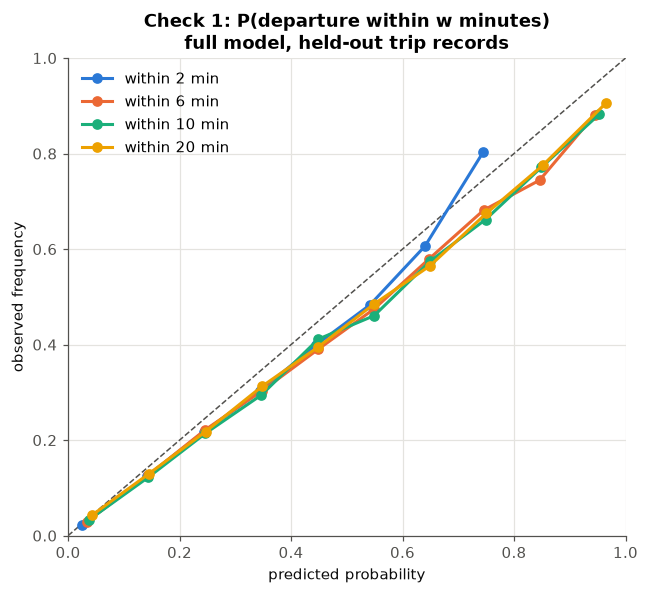

In [36]:
p_full = trip_predictions["3. Time of day + weather/season"]
fig, ax = plt.subplots(figsize=(6, 5.5))
plot_reliability(ax, [(f"within {w_min} min", p_full[q_w == w_min], q_observed[q_w == w_min]) for w_min in WINDOWS_MIN],
                 "Check 1: P(departure within w minutes)\nfull model, held-out trip records")
plt.tight_layout()
plt.show()

**Waiting-time check.** For the same moments, the actual time $T$ to the next departure is converted with the model: $u = 1 - e^{-\Lambda(t,\,t+T)}$. If the model's waiting-time distribution were right, $u$ would be uniform (a flat histogram); a pile-up near 1 means departures came later than predicted. When no departure happens within 2 hours, $u$ is drawn uniformly above its known lower bound.

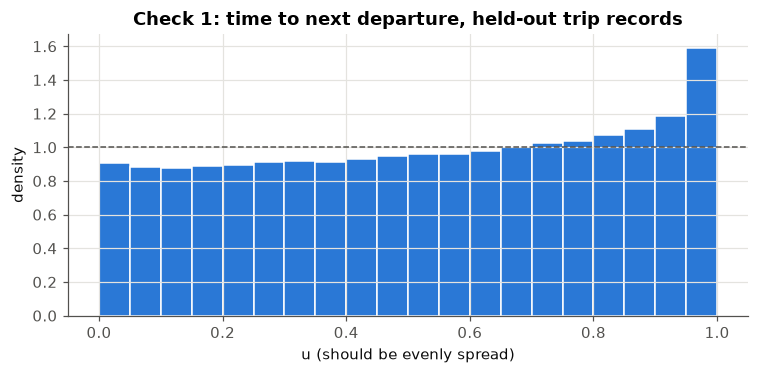

In [37]:
gap = minutes_to_next_departure(q_station, q_t, PIT_HORIZON_MIN)
seen = ~np.isnan(gap)
u = np.empty(len(gap))
u[seen] = 1 - np.exp(-expected_departures(q_station[seen], q_t[seen], gap[seen]))
u_floor = 1 - np.exp(-expected_departures(q_station[~seen], q_t[~seen], PIT_HORIZON_MIN))
u[~seen] = rng.uniform(u_floor, 1)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(u, bins=20, range=(0, 1), color=SERIES_COLORS[0], edgecolor="white", density=True)
ax.axhline(1, linestyle="--", color=INK_SECONDARY, linewidth=1)
ax.set_xlabel("u (should be evenly spread)"); ax.set_ylabel("density")
ax.set_title("Check 1: time to next departure, held-out trip records")
plt.tight_layout()
plt.show()

## 6. Station status snapshots (for out-of-sample testing)

The status data records every station every 2 minutes: open docks, and whether the station is installed, renting and returning. A one-time cache keeps days 15–end of each month and, for each snapshot, the station name, fetch time (New York time), open docks, whether the station was working, and how old the station's report was.

Each month becomes a grid of **stations × 2-minute snapshots**:
- Snapshots are fetched about 22 seconds after each even minute. Each is placed at the next grid time, so the grid never shows a state before it was collected.
- A report older than `MAX_REPORT_AGE_MIN`, or without a report time, counts as missing. Most of these come from a feed freeze of about 2.3 days in July.
- A single missing snapshot between two usable ones takes the previous value. Snapshots where the station wasn't working are never filled.
- A station is **full** when it shows 0 open docks.

Stations are matched to the trip data by name; the match rate is printed below.

In [38]:
# Download only the 2024 file from Kaggle (4.2 GB), if it isn't here yet. Public dataset: no login needed.
# kagglehub saves into its own cache folder (~/.cache/kagglehub), so the file is then moved to STATUS_PATH.
if not os.path.exists(STATUS_PATH):
    import kagglehub
    import shutil
    downloaded = kagglehub.dataset_download("rosenthal/citi-bike-stations", path=os.path.basename(STATUS_PATH))
    os.makedirs(os.path.dirname(STATUS_PATH), exist_ok=True)
    shutil.move(downloaded, STATUS_PATH)
print(f"status file: {STATUS_PATH} ({os.path.getsize(STATUS_PATH) / 1e9:.1f} GB)")

status file: data/status/citi_bike_stations_2024.parquet (4.2 GB)


In [39]:
def build_status_cache(status_path, cache_dir, first_day):
    """One-time step (a few minutes): slim copy of the status file, one folder per month.
    If the cache folder already exists it is reused as-is. Delete it after changing STATUS_PATH or RECAL_FIRST_DAY."""
    if os.path.exists(cache_dir):
        print(f"reusing existing cache: {cache_dir} (delete it to rebuild)")
        return
    con = duckdb.connect()
    con.execute("SET TimeZone = 'UTC'")      # so timestamps are interpreted as UTC, as documented for this dataset
    con.execute(f"""
        COPY (
            SELECT station_name,
                   month(local_ts) AS month,
                   (epoch(local_ts) - epoch(TIMESTAMP '2024-01-01')) / 60.0 AS t_min,
                   num_docks_available::SMALLINT AS docks,
                   coalesce(is_installed::BOOLEAN AND is_renting::BOOLEAN AND is_returning::BOOLEAN, false) AS working,
                   (epoch(fetched_at::TIMESTAMPTZ) - epoch(station_status_last_reported::TIMESTAMPTZ)) / 60.0 AS report_age_min
            FROM (SELECT *, timezone('America/New_York', fetched_at::TIMESTAMPTZ) AS local_ts
                  FROM read_parquet('{status_path}'))
            WHERE year(local_ts) = 2024
              AND day(local_ts) >= {first_day}
              AND num_docks_available IS NOT NULL
        ) TO '{cache_dir}' (FORMAT parquet, PARTITION_BY (month))
    """)
    con.close()
    print(f"cache written: {cache_dir}")


build_status_cache(STATUS_PATH, STATUS_CACHE_DIR, first_day=RECAL_FIRST_DAY)

reusing existing cache: data/status/status_2024_cache (delete it to rebuild)


In [40]:
con = duckdb.connect()
con.register("station_lookup", pd.DataFrame({"station_name": stations, "station": np.arange(n_stations)}))

status_names = con.execute(f"""
    SELECT station_name, count(*) AS snapshots
    FROM read_parquet('{STATUS_CACHE_DIR}/*/*.parquet') GROUP BY 1
""").df()
matched = status_names.station_name.isin(station_idx)
in_status = np.isin(stations, status_names.station_name)
print(f"status station names that match a trip station: {matched.mean():.1%} "
      f"({status_names.snapshots[matched].sum() / status_names.snapshots.sum():.1%} of snapshots)")
print(f"trip stations found in the status data: {in_status.mean():.1%} "
      f"({Y.sum(axis=0)[in_status].sum() / Y.sum():.1%} of 2024 departures)")

status station names that match a trip station: 98.9% (99.0% of snapshots)
trip stations found in the status data: 99.3% (100.0% of 2024 departures)


In [41]:
def load_status_block(con, month, first_day, last_day=None):
    """Grid of open docks for one month's day range: shape (n_stations, n_snapshots), -1 = no usable data.
    Column j is the state known at start_min + 2j minutes."""
    start = pd.Timestamp(2024, month, first_day)
    end = start + pd.offsets.MonthBegin(1) if last_day is None else pd.Timestamp(2024, month, last_day) + pd.Timedelta(days=1)
    start_min = (start - YEAR_START) / pd.Timedelta(minutes=1)
    end_min = (end - YEAR_START) / pd.Timedelta(minutes=1)
    n_polls = int(round((end_min - start_min) / STEP_MIN))
    MISSING, NOT_WORKING = -1, -2
    docks = np.full((n_stations, n_polls), MISSING, dtype=np.int16)
    n_stale = 0

    month_files = f"{STATUS_CACHE_DIR}/month={month}/*.parquet"
    if glob.glob(month_files):
        snap = con.execute(f"""
            SELECT l.station, s.t_min, s.docks, s.working, s.report_age_min
            FROM read_parquet('{month_files}') s JOIN station_lookup l USING (station_name)
            WHERE s.t_min > ? AND s.t_min < ?
        """, [start_min - STEP_MIN, end_min]).df()
        # Each snapshot goes to the first grid time at or after it was fetched, so no state is visible before it was collected.
        # If two land on the same grid time (rare), the later one is kept.
        snap["poll"] = np.ceil((snap.t_min - start_min) / STEP_MIN).astype(np.int64)
        snap = snap[snap.poll < n_polls].sort_values("t_min").drop_duplicates(["station", "poll"], keep="last")
        working = snap.working.to_numpy()
        fresh = snap.report_age_min.le(MAX_REPORT_AGE_MIN).to_numpy()     # old or unknown report times count as missing
        n_stale = int((working & ~fresh).sum())
        value = np.where(~working, NOT_WORKING, np.where(fresh, snap.docks.to_numpy(), MISSING))
        docks[snap.station.to_numpy(), snap.poll.to_numpy()] = value
        # Daylight-saving changes (Mar 10, Nov 3) fall outside the day ranges used here, so local times never repeat.

    # A single missing snapshot between two usable ones takes the previous value (a dock that opened during the gap
    # is counted at the next snapshot, at most 2 minutes late). Recorded outages are never filled.
    single_gap = (docks[:, 1:-1] == MISSING) & (docks[:, :-2] >= 0) & (docks[:, 2:] >= 0)
    docks[:, 1:-1][single_gap] = docks[:, :-2][single_gap]
    docks[docks == NOT_WORKING] = MISSING     # from here on, -1 means "no usable data"
    return {"month": month, "start_min": start_min, "docks": docks, "n_stale": n_stale}


test_blocks = [load_status_block(con, m, TEST_FIRST_DAY) for m in MONTHS]
recal_blocks = [load_status_block(con, m, RECAL_FIRST_DAY, TRAIN_LAST_DAY) for m in MONTHS]

for name, blocks in [("test (days 22-end)", test_blocks), ("recalibration (days 15-21)", recal_blocks)]:
    known = sum((block["docks"] != -1).sum() for block in blocks)
    full = sum((block["docks"] == 0).sum() for block in blocks)
    stale = sum(block["n_stale"] for block in blocks)
    print(f"{name}: {known:,} station-snapshots with usable data, {full / max(known, 1):.1%} of them full; "
          f"{stale:,} stale reports treated as missing")

test (days 22-end): 173,658,630 station-snapshots with usable data, 6.7% of them full; 3,529,371 stale reports treated as missing
recalibration (days 15-21): 130,767,670 station-snapshots with usable data, 6.8% of them full; 107,909 stale reports treated as missing


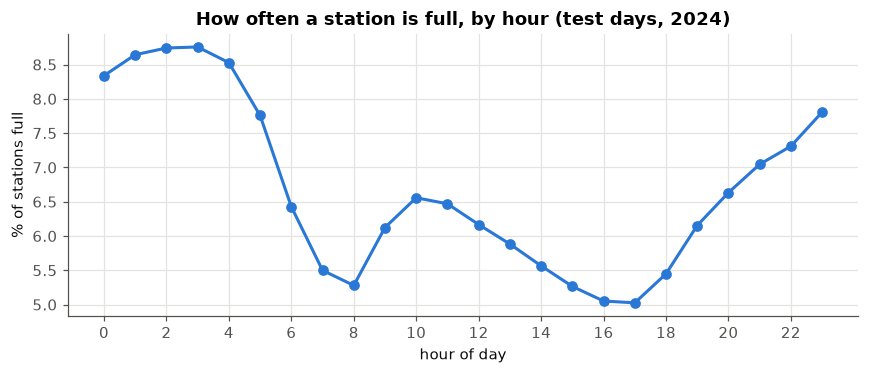

In [42]:
# Context: when are full stations most common? That's when the wait-or-ride-on decision matters most. (test days)
hour_known, hour_full = np.zeros(24), np.zeros(24)
for b in test_blocks:
    hours = ((b["start_min"] + STEP_MIN * np.arange(b["docks"].shape[1])) % 1440 // 60).astype(int)
    np.add.at(hour_known, hours, (b["docks"] != -1).sum(axis=0))
    np.add.at(hour_full, hours, (b["docks"] == 0).sum(axis=0))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(range(24), 100 * hour_full / np.maximum(hour_known, 1), marker="o", markersize=6, color=SERIES_COLORS[0])
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("hour of day"); ax.set_ylabel("% of stations full")
ax.set_title("How often a station is full, by hour (test days, 2024)")
plt.tight_layout()
plt.show()

## 7. Check 2 (out of sample): real full stations

Every snapshot where a station was full is a moment when a rider could have arrived and found no dock. Full-station moments on the **test days** are sampled with the same probability in every month, and for each one we record:
- `wait_min`: minutes until the first snapshot showing an open dock (exact to the 2-minute step);
- `full_through_min`: how long it's *known* to have stayed full, when the data stops before a dock opens (a censored moment);
- `data_ok_min`: minutes of unbroken usable snapshots after the moment, whatever they show;
- `elapsed_full_min`: how long the station had already been full.

**Data gaps.** Dropping moments whose outcome is unknown would favor quick openings, so the fixed-window checks keep a moment only if `data_ok_min` ≥ *w*, a rule about data availability rather than the outcome. This assumes that gaps in the data aren't related to how quickly docks open. The survival curves use censored moments through the Kaplan–Meier estimator, which makes the same assumption.

In [43]:
PERIOD_LABELS = ["Night 0-7h", "AM peak 7-10h", "Midday 10-16h", "PM peak 16-20h", "Evening 20-24h"]


def next_stop_index(docks):
    """For every (station, snapshot): the first snapshot at or after it where the station is NOT full
    (an open dock, or no data). Equals n_snapshots if it stays full to the end of the block."""
    n = docks.shape[1]
    idx = np.where(docks != 0, np.arange(n, dtype=np.int32), np.int32(n))
    return np.minimum.accumulate(idx[:, ::-1], axis=1)[:, ::-1]


def prev_stop_index(docks):
    """For every (station, snapshot): the last snapshot at or before it where the station was NOT full (-1 if none).
    No-data snapshots count as "not full" here, so `elapsed_full_min` restarts after a data gap (a lower bound)."""
    n = docks.shape[1]
    idx = np.where(docks != 0, np.arange(n, dtype=np.int32), np.int32(-1))
    return np.maximum.accumulate(idx, axis=1)


def next_missing_index(docks):
    """For every (station, snapshot): the first snapshot at or after it with no data. n_snapshots if there is none."""
    n = docks.shape[1]
    idx = np.where(docks == -1, np.arange(n, dtype=np.int32), np.int32(n))
    return np.minimum.accumulate(idx[:, ::-1], axis=1)[:, ::-1]


def full_station_events(blocks, n_target):
    """Sample of moments when a station was full, with what happened next.
    Every full snapshot has the same chance of being picked, whichever month it is in."""
    n_full = sum(int((block["docks"] == 0).sum()) for block in blocks)
    pick_prob = min(1.0, n_target / max(n_full, 1))
    frames = []
    for b, block in enumerate(blocks):
        docks = block["docks"]
        n = docks.shape[1]
        s, j = np.nonzero(docks == 0)
        keep = rng.random(len(s)) < pick_prob
        s, j = s[keep], j[keep]
        if len(s) == 0:
            continue
        k = next_stop_index(docks)[s, j]          # first snapshot after j that is open or has no data
        opened = (k < n) & (docks[s, np.minimum(k, n - 1)] > 0)
        frames.append(pd.DataFrame({
            "block": b,
            "station": s,
            "poll": j,
            "t_min": block["start_min"] + STEP_MIN * j,
            "opened": opened,
            "wait_min": np.where(opened, STEP_MIN * (k - j), np.nan),
            "full_through_min": STEP_MIN * (k - j - 1),
            "data_ok_min": STEP_MIN * (next_missing_index(docks)[s, j] - j - 1),
            "elapsed_full_min": STEP_MIN * (j - prev_stop_index(docks)[s, j] - 1),
        }))
    events = pd.concat(frames, ignore_index=True)
    events["hour"] = (events.t_min % 1440 // 60).astype(int)
    events["period"] = pd.cut(events.hour, [-1, 6, 9, 15, 19, 23], labels=PERIOD_LABELS)
    return events


def outcome_within(events, w_min):
    """1 = a dock opened within w minutes, 0 = still full at w minutes,
    NaN = the snapshots have a gap inside the window (decided by data availability only, never by the outcome)."""
    complete = events.data_ok_min >= w_min
    opened_by_w = events.opened & (events.wait_min <= w_min)
    return np.where(complete, opened_by_w.astype(float), np.nan)


test_events = full_station_events(test_blocks, N_EVENTS)
print(f"{len(test_events):,} full-station moments sampled from the test days")
print(f"dock opened before the data stopped: {test_events.opened.mean():.1%}")
test_events.head()

239,922 full-station moments sampled from the test days
dock opened before the data stopped: 96.5%


,block,station,poll,t_min,opened,wait_min,full_through_min,data_ok_min,elapsed_full_min,hour,period
0,0,0,597,31434.0,True,18.0,16,13204,8,19,PM peak 16-20h
1,0,0,599,31438.0,True,14.0,12,13200,12,19,PM peak 16-20h
2,0,0,607,31454.0,True,42.0,40,13184,0,20,Evening 20-24h
3,0,0,652,31544.0,True,10.0,8,13094,36,21,Evening 20-24h
4,0,0,1264,32768.0,True,8.0,6,11870,26,18,PM peak 16-20h


In [44]:
S_trip = survival_curves(test_events.station.to_numpy(), test_events.t_min.to_numpy())


def calibration_scores(events, survival, label):
    rows = []
    for w_min in WINDOWS_MIN:
        y = outcome_within(events, w_min)
        ok = ~np.isnan(y)
        p = 1 - survival[ok, w_min // STEP_MIN]
        rows.append({"model": label, "window (min)": w_min, "n": ok.sum(),
                     "avg predicted": p.mean(), "actually happened": y[ok].mean(), "Brier": brier(p, y[ok])})
    return pd.DataFrame(rows)


check2_scores = calibration_scores(test_events, S_trip, "trip-based")
check2_scores.round(3)

,model,window (min),n,avg predicted,actually happened,Brier
0,trip-based,2,239825,0.049,0.037,0.035
1,trip-based,6,239650,0.119,0.097,0.075
2,trip-based,10,239478,0.168,0.144,0.097
3,trip-based,20,239060,0.253,0.228,0.123


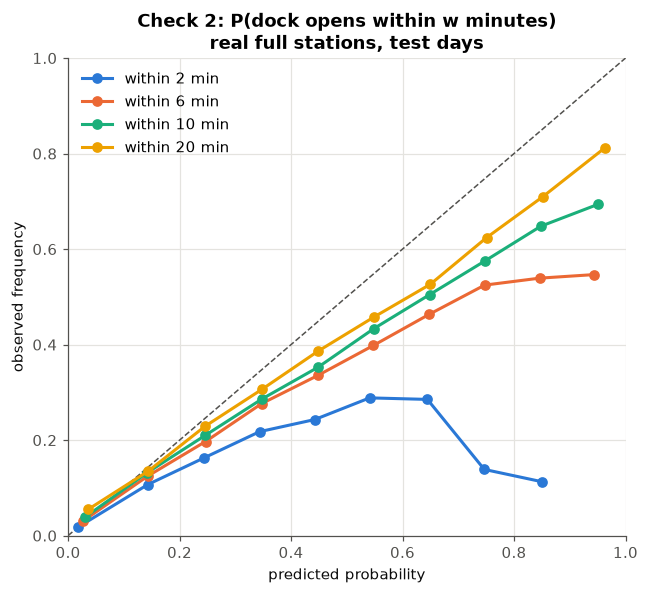

In [45]:
curves = []
for w_min in WINDOWS_MIN:
    y = outcome_within(test_events, w_min)
    ok = ~np.isnan(y)
    curves.append((f"within {w_min} min", 1 - S_trip[ok, w_min // STEP_MIN], y[ok]))

fig, ax = plt.subplots(figsize=(6, 5.5))
plot_reliability(ax, curves, "Check 2: P(dock opens within w minutes)\nreal full stations, test days")
plt.tight_layout()
plt.show()

**Survival curves.** The dark line is what actually happened (Kaplan–Meier: the share of full-station moments still full after *u* minutes). The colored lines are the models' predictions for the same moments. A model line below the dark one means docks opened more slowly than predicted.

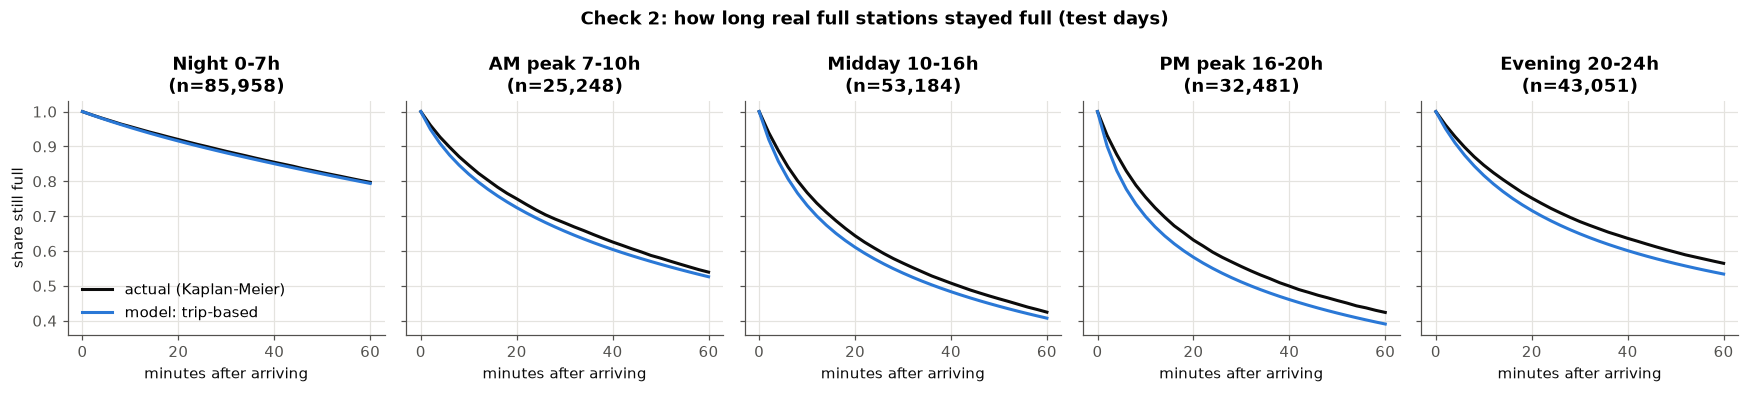

In [46]:
def kaplan_meier(events, max_min=MAX_WAIT_MIN):
    """Share of full-station moments still full after u minutes (u = 0, 2, ..., max_min), allowing for data gaps."""
    times = np.arange(0, max_min + STEP_MIN, STEP_MIN)
    opened = events.opened.to_numpy()
    open_time = events.wait_min.to_numpy()[opened]
    known_full_until = events.full_through_min.to_numpy()[~opened]
    still_full = [1.0]
    for u in times[1:]:
        at_risk = (open_time >= u).sum() + (known_full_until >= u).sum()
        opened_now = (open_time == u).sum()
        still_full.append(still_full[-1] * (1 - opened_now / at_risk) if at_risk > 0 else still_full[-1])
    return times, np.array(still_full)


def plot_survival_by_period(events, model_curves, title):
    """model_curves: list of (label, survival array aligned with events)."""
    fig, axes = plt.subplots(1, len(PERIOD_LABELS), figsize=(16, 3.6), sharey=True)
    minutes = np.arange(0, MAX_WAIT_MIN + STEP_MIN, STEP_MIN)
    for ax, period in zip(axes, PERIOD_LABELS):
        in_period = (events.period == period).to_numpy()
        if in_period.sum() == 0:
            ax.set_title(f"{period}\n(no data)")
            continue
        times, km = kaplan_meier(events[in_period])
        ax.plot(times, km, color=INK, label="actual (Kaplan-Meier)")
        for color, (label, S) in zip(SERIES_COLORS, model_curves):
            ax.plot(minutes, S[in_period].mean(axis=0), color=color, label=label)
        ax.set_title(f"{period}\n(n={in_period.sum():,})")
        ax.set_xlabel("minutes after arriving")
    axes[0].set_ylabel("share still full")
    axes[0].legend(loc="lower left")
    fig.suptitle(title, fontweight="bold")
    plt.tight_layout()
    plt.show()


plot_survival_by_period(test_events, [("model: trip-based", S_trip)], "Check 2: how long real full stations stayed full (test days)")

**What can make reality differ from the trip-based model**
- **Other riders compete for the freed dock.** When a bike leaves, someone else arriving may take that dock first, so the station stays full. This makes reality *slower* than the model.
- **Rebalancing.** Trucks and valets remove bikes from full stations. Those removals aren't in trip records, so this makes reality *faster* than the model.
- **Very short openings are missed.** A dock that opens and is refilled within 2 minutes never shows up in a snapshot. This makes reality look *slower*.
- **"Full" stations that don't recover.** A station showing 0 open docks because of broken docks may not behave like a normal full station.

Section 8 measures the net effect of all of these and corrects for it.

## 8. Recalibration: what trip data misses

A small correction fitted on status snapshots from **days 15–21** (inside the training period). For each full snapshot: did a dock open by the next snapshot, 2 minutes later?

$$P(\text{dock opens in next 2 min}) = 1 - \exp\!\big(-e^{a}\,\Lambda_2^{\,b}\,(1+\text{minutes already full})^{c}\big)$$

where $\Lambda_2$ is the trip model's expected departures in those 2 minutes. This is a complementary log-log model with three numbers, fitted by maximum likelihood. With $a = 0,\ b = 1,\ c = 0$ it reproduces the trip-based model, apart from the tiny `LAM_FLOOR` added to $\Lambda_2$ to keep the log finite.
- $e^{a}$ scales all opening rates; $b$ says how proportionally real openings follow the trip-based rate; $c$ says whether stations that have been full longer open more slowly.
- How long a station has been full is only known from live data, so a second version with $c = 0$ is fitted for riders without it.

$b < 1$ can also partly reflect noise in the estimated rates, and $c$ mixes time already full with differences between stations (stations that stay full for long may simply be quieter).

In [47]:
def fit_recalibration(lam, elapsed, opened_next, use_elapsed=True):
    """Maximum-likelihood fit of (a, b, c) in the complementary log-log model above. With use_elapsed=False, c is fixed at 0."""
    columns = [np.ones_like(lam), np.log(lam + LAM_FLOOR)] + ([np.log1p(elapsed)] if use_elapsed else [])
    features = np.column_stack(columns)

    def negative_log_likelihood(params):
        hazard = np.exp(np.clip(features @ params, -30, 5))
        log_p_open = np.log(-np.expm1(-hazard) + 1e-12)       # log(1 - exp(-hazard))
        log_p_stay = -hazard
        return -np.mean(opened_next * log_p_open + (1 - opened_next) * log_p_stay)

    start = np.array([0.0, 1.0, 0.0])[:features.shape[1]]
    params = minimize(negative_log_likelihood, x0=start, method="L-BFGS-B").x
    return params if use_elapsed else np.append(params, 0.0)


recal_events = full_station_events(recal_blocks, N_EVENTS)
r = recal_events[recal_events.data_ok_min >= STEP_MIN]        # keep snapshots whose next snapshot has data (whatever it shows)
opened_next = (r.opened & (r.wait_min == STEP_MIN)).to_numpy().astype(float)
lam_2min = expected_departures(r.station.to_numpy(), r.t_min.to_numpy(), STEP_MIN)
elapsed_full = r.elapsed_full_min.to_numpy()

recal_params = fit_recalibration(lam_2min, elapsed_full, opened_next)                                # uses live data
recal_params_no_live = fit_recalibration(lam_2min, elapsed_full, opened_next, use_elapsed=False)    # for riders without it
a, b, c = recal_params
print(f"fitted on {len(r):,} full-station snapshots (days 15-21)")
print(f"with elapsed time:    a = {a:+.2f}   b = {b:.2f}   c = {c:+.2f}")
print(f"without elapsed time: a = {recal_params_no_live[0]:+.2f}   b = {recal_params_no_live[1]:.2f}")
print("(a = 0, b = 1, c = 0 would mean the trip model needs no correction)")
for lam in [0.05, 0.2, 0.5]:
    ratio = np.exp(a) * (lam + LAM_FLOOR) ** b / lam
    print(f"  where trips predict {lam} departures per 2 min, docks open at {ratio:.2f}x that rate (station that just filled)")
ELAPSED_EXAMPLE_MIN = 30
print(f"  after {ELAPSED_EXAMPLE_MIN} minutes already full, the opening rate is "
      f"{(1 + ELAPSED_EXAMPLE_MIN) ** c:.2f}x the rate of a station that just filled")

fitted on 239,578 full-station snapshots (days 15-21)
with elapsed time:    a = -0.53   b = 0.61   c = -0.22
without elapsed time: a = -0.77   b = 0.77
(a = 0, b = 1, c = 0 would mean the trip model needs no correction)
  where trips predict 0.05 departures per 2 min, docks open at 1.90x that rate (station that just filled)
  where trips predict 0.2 departures per 2 min, docks open at 1.10x that rate (station that just filled)
  where trips predict 0.5 departures per 2 min, docks open at 0.77x that rate (station that just filled)
  after 30 minutes already full, the opening rate is 0.47x the rate of a station that just filled


In [48]:
S_recal = survival_curves(test_events.station.to_numpy(), test_events.t_min.to_numpy(),
                          test_events.elapsed_full_min.to_numpy(), recal=recal_params)
S_recal_no_live = survival_curves(test_events.station.to_numpy(), test_events.t_min.to_numpy(), recal=recal_params_no_live)
check2_all = pd.concat([check2_scores,
                        calibration_scores(test_events, S_recal, "recalibrated"),
                        calibration_scores(test_events, S_recal_no_live, "recalibrated, no elapsed time")])
print("Out-of-sample on test days:")
check2_all.pivot(index="model", columns="window (min)", values=["Brier", "avg predicted", "actually happened"]).round(3)

Out-of-sample on test days:


Brier                      avg predicted  \
window (min)                      2      6      10     20            2    
model                                                                     
recalibrated                   0.033  0.070  0.091  0.116         0.038   
recalibrated, no elapsed time  0.033  0.072  0.093  0.120         0.039   
trip-based                     0.035  0.075  0.097  0.123         0.049   

                                                   actually happened         \
window (min)                      6      10     20                2      6    
model                                                                         
recalibrated                   0.097  0.144  0.231             0.037  0.097   
recalibrated, no elapsed time  0.103  0.156  0.254             0.037  0.097   
trip-based                     0.119  0.168  0.253             0.037  0.097   

                                             
window (min)                      10     20  
model                                        
recalibrated                   0.144  0.228  
recalibrated, no elapsed time  0.144  0.228  
trip-based                     0.144  0.228

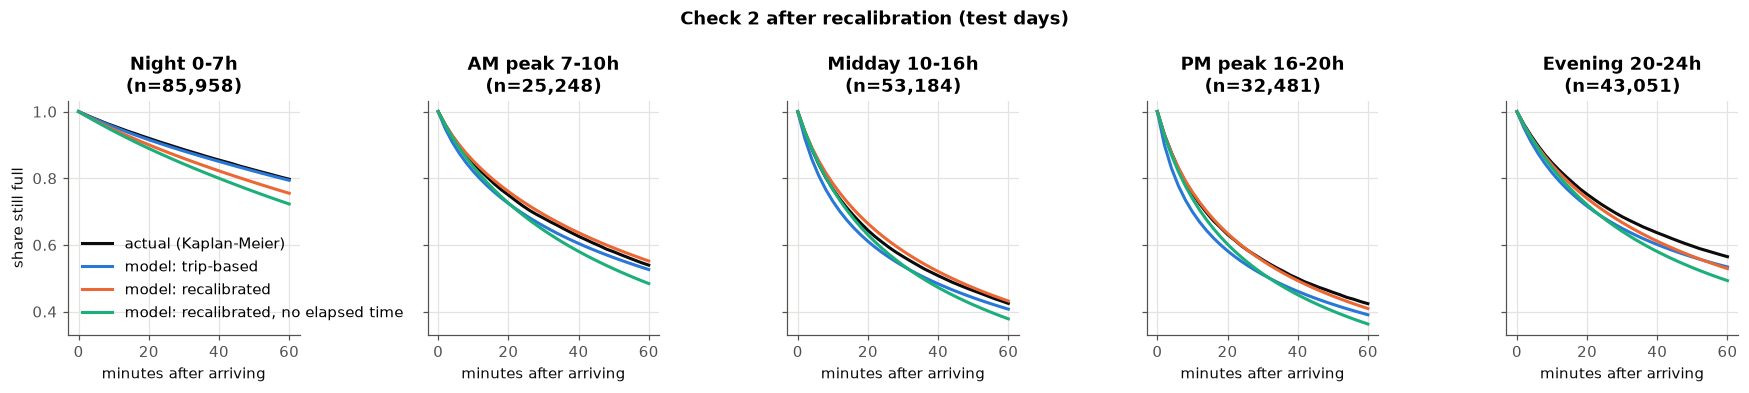

In [49]:
plot_survival_by_period(test_events, [("model: trip-based", S_trip), ("model: recalibrated", S_recal),
                                      ("model: recalibrated, no elapsed time", S_recal_no_live)],
                        "Check 2 after recalibration (test days)")

## 9. The decision rule, replayed on real full stations

**The rule.** At a full station, compare staying with riding to one of the nearest other stations (up to `NEIGHBOR_K = 5` within `NEIGHBOR_RADIUS_M = 500` m):

$$\text{expected time} = \text{ride there} + \text{expected wait for a dock (capped at 60 min)} + \text{walk back}$$

and pick the smallest. Distances are straight-line × 1.3; riding is 200 m/min and walking 80 m/min. Taking the K nearest *within a radius* keeps the choice small in dense Midtown and avoids kilometer-long detours in the outer boroughs.

**What each rule knows when deciding**

| Rule | Information used |
|---|---|
| Always wait | nothing |
| Always ride to nearest | distances; stays if no other station is within 500 m |
| Nearest showing open docks | live open-dock counts: rides to the nearest candidate showing a dock, or waits if none does |
| Model: trip-based | trip-based rates; your station is full, and another is full with the probability measured on days 15–21 when your station was full |
| Model: recalibrated | the same, with the recalibration fitted without elapsed time |
| Model: … + live | live open-dock counts: a station showing a dock counts as no wait. The recalibrated version also uses how long each full station has been full, which a system polling the live feed would know |
| Hindsight best | what actually happened: the best any rule could do |

The model rules use the weather observed over the following hour, a stand-in for a short-term forecast.

**Which moments are replayed.** Full-station moments are sampled with the same probability across the test days. A moment is kept only if every candidate station (the full station and its up to 5 nearest neighbors within 500 m) was in service and reporting from the moment of deciding until 60 minutes after the rider would arrive. All rules are scored on the same moments, and no rule needs to know which stations are out of service; the results describe moments when the nearby stations were working.

**Scoring.** Riders reach a station at the first snapshot after their ride ends, so ride time is rounded up to whole 2-minute steps, in the models' estimates and the actual outcome alike. If that snapshot shows an open dock the wait is 0; otherwise it is the time until one does. Total = ride + wait + walk back. **Waits are capped at 60 minutes.** The total is ride + wait at the chosen station + walk back, with the wait capped at 60 minutes, so means and percentiles describe this capped total. The share of riders still waiting after 60 minutes at the station they chose (not counting the ride there) is shown separately.

**Per rider.** Each moment is weighted by how many riders typically arrive to return a bike at that station at that time (Section 9b).

In [50]:
EARTH_RADIUS_M = 6_371_000

coords = station_coords.reindex(stations)[["lat", "lon"]].to_numpy()
has_coords = np.isfinite(coords).all(axis=1)
has_status = np.zeros(n_stations, dtype=bool)
for block in recal_blocks:                                # days 15-21, so the test days don't decide the candidates
    has_status |= (block["docks"] != -1).any(axis=1)
candidates = np.flatnonzero(has_coords & has_status)      # stations a rider could be sent to

tree = BallTree(np.radians(coords[candidates]), metric="haversine")
query = np.flatnonzero(has_coords)
dist, ind = tree.query(np.radians(coords[query]), k=min(NEIGHBOR_K + 1, len(candidates)))
dist_m, neighbor_ids = dist * EARTH_RADIUS_M, candidates[ind]

neighbors = np.full((n_stations, NEIGHBOR_K), -1)               # -1 = no neighbor in that slot
neighbor_dist_m = np.full((n_stations, NEIGHBOR_K), np.nan)
for row, s in enumerate(query):
    keep = np.flatnonzero((neighbor_ids[row] != s) & (dist_m[row] <= NEIGHBOR_RADIUS_M))[:NEIGHBOR_K]
    neighbors[s, :len(keep)] = neighbor_ids[row, keep]
    neighbor_dist_m[s, :len(keep)] = dist_m[row, keep]

n_neighbors = (neighbors[has_status] >= 0).sum(axis=1)
print("number of neighbors within the radius (stations with status data):")
print(pd.Series(n_neighbors).value_counts().sort_index().rename("stations").to_string())

number of neighbors within the radius (stations with status data):
0      12
1      17
2      30
3      50
4     103
5    2043


### 9a. Without live data: how likely is a nearby station to be full too?
Measured on days 15–21: of the snapshots when a station was full (and its neighbor was reporting), the share in which the neighbor was full too. Pairs with little data are shrunk toward the neighbor's overall share of time full (`NEIGHBOR_PRIOR_SNAPSHOTS`).

In [51]:
def neighbor_full_rates(blocks, neighbors, prior_snapshots=NEIGHBOR_PRIOR_SNAPSHOTS):
    """P(neighbor is full | this station is full) for every station and each of its neighbors, shape (n_stations, K).
    Measured on the recalibration-week snapshots and shrunk toward the neighbor's overall share of time full,
    as if `prior_snapshots` extra snapshots had been seen at that share. Also returns each station's share of time full."""
    k_max = neighbors.shape[1]
    safe = np.maximum(neighbors, 0)                          # placeholder index for empty neighbor slots (masked at the end)
    station_full_neighbor_known = np.zeros((n_stations, k_max))
    both_full = np.zeros((n_stations, k_max))
    full_count, known_count = np.zeros(n_stations), np.zeros(n_stations)
    for block in blocks:
        full, known = block["docks"] == 0, block["docks"] != -1
        full_count += full.sum(axis=1)
        known_count += known.sum(axis=1)
        for k in range(k_max):
            station_full_neighbor_known[:, k] += (full & known[safe[:, k]]).sum(axis=1)
            both_full[:, k] += (full & full[safe[:, k]]).sum(axis=1)
    share_full = np.divide(full_count, known_count, out=np.zeros(n_stations), where=known_count > 0)
    rate = (both_full + prior_snapshots * share_full[safe]) / (station_full_neighbor_known + prior_snapshots)
    return np.where(neighbors >= 0, rate, np.nan), share_full


neighbor_full_given_full, share_full = neighbor_full_rates(recal_blocks, neighbors)
nearest = neighbors[:, 0]
has_nearest = has_status & (nearest >= 0)
print(f"when a station is full, its nearest neighbor is also full {np.mean(neighbor_full_given_full[has_nearest, 0]):.1%} of the time")
print(f"at a random moment, those same neighbors are full {np.mean(share_full[nearest[has_nearest]]):.1%} of the time")


when a station is full, its nearest neighbor is also full 20.9% of the time
at a random moment, those same neighbors are full 6.8% of the time


### 9b. Counting riders, not moments
Full-station moments are sampled evenly over time, but riders don't arrive evenly: few people return bikes at 3 am. Each moment is weighted by the station's average arrivals for that half-hour and day type on training days (the same estimator as the departure model), times the weather/season multiplier fitted for departures. Trip records undercount arrivals at often-full stations (riders who find them full end their trip elsewhere), so those stations get somewhat less weight than their true demand.

In [52]:
# Arrivals per station per 30-minute slot (from Section 2's df_enter_final), aligned with the departure arrays
arrivals = (df_enter_final[df_enter_final.index.year == 2024]
            .reindex(index=dates, columns=stations, fill_value=0)
            .to_numpy(dtype=np.float32))
arrival_base = fit_base_rates(arrivals, active, is_train, profile_key, multiplier)   # same estimator as the departure model


def expected_arrivals_per_min(station, t_min):
    """Riders expected to arrive to return a bike at `station`, per minute, around t_min
    (training-day average for that time slot, times the weather/season multiplier)."""
    slot = np.clip(np.asarray(t_min) // 30, 0, n_slots - 1).astype(np.int64)
    return arrival_base[profile_key[slot], station] * multiplier[slot] / 30


In [53]:
POLICIES = [
    "Always wait",
    "Always ride to nearest",
    "Nearest showing open docks",
    "Model: trip-based",
    "Model: trip-based + live",
    "Model: recalibrated",
    "Model: recalibrated + live",
    "Hindsight best",
]


def replay_block(block, events):
    """Run every decision rule on a set of full-station moments from one month's test days."""
    docks = block["docks"]
    n_polls = docks.shape[1]
    next_stop, next_missing, prev_stop = next_stop_index(docks), next_missing_index(docks), prev_stop_index(docks)
    s0, poll, t0 = events.station.to_numpy(), events.poll.to_numpy(), events.t_min.to_numpy()
    n = len(s0)

    # Options: column 0 = stay; columns 1..K = nearest other stations in distance order (-1 = none in that slot)
    options = np.column_stack([s0, neighbors[s0]])
    exists = options >= 0
    station = np.maximum(options, 0)                      # placeholder index for empty slots (masked with `exists`)
    dist = np.nan_to_num(np.column_stack([np.zeros(n), neighbor_dist_m[s0]]))

    # Riders reach a station at the first snapshot after their ride ends: ride time is rounded up to whole steps
    ride_steps = np.ceil(dist * DETOUR_FACTOR / BIKE_SPEED_M_MIN / STEP_MIN).astype(int)
    ride_min = STEP_MIN * ride_steps
    walk_min = dist * DETOUR_FACTOR / WALK_SPEED_M_MIN
    travel_min = ride_min + walk_min
    decide = poll[:, None]
    arrive = decide + ride_steps

    # Keep a moment only if every option was in service and reporting from the decision until MAX_WAIT_MIN after arrival
    covered = next_missing[station, decide] > arrive + N_STEPS
    keep = (covered | ~exists).all(axis=1)

    # What actually happened: the first snapshot at or after arrival showing an open dock (capped at MAX_WAIT_MIN)
    steps_waited = next_stop[station, np.minimum(arrive, n_polls - 1)] - arrive
    resolved = steps_waited <= N_STEPS
    real_wait = np.where(resolved, STEP_MIN * steps_waited, MAX_WAIT_MIN)
    real_total = np.where(exists, travel_min + real_wait, np.inf)

    # Live information at the moment of deciding: open docks, and how long each full station has been full
    open_now = exists & (docks[station, decide] > 0)
    full_now = exists & (docks[station, decide] == 0)
    elapsed_now = np.where(full_now, STEP_MIN * (decide - prev_stop[station, decide] - 1), 0)

    # Each model's expected total time
    arrive_t = t0[:, None] + ride_min

    def wait_if_full(recal, elapsed_at_arrival):
        S = survival_curves(station.ravel(), arrive_t.ravel(), elapsed_at_arrival.ravel(), recal=recal)
        return expected_wait(S).reshape(options.shape)

    p_full = np.column_stack([np.ones(n), np.nan_to_num(neighbor_full_given_full[s0])])   # without live data (Section 9a)
    W_trip = wait_if_full(None, np.zeros(options.shape))
    W_recal_no_live = wait_if_full(recal_params_no_live, np.zeros(options.shape))
    W_recal_live = wait_if_full(recal_params, elapsed_now + ride_min)
    expected_cost = {
        "Model: trip-based": travel_min + p_full * W_trip,
        "Model: trip-based + live": travel_min + np.where(open_now, 0, W_trip),
        "Model: recalibrated": travel_min + p_full * W_recal_no_live,
        "Model: recalibrated + live": travel_min + np.where(open_now, 0, W_recal_live),
    }
    expected_cost = {name: np.where(exists, cost, np.inf) for name, cost in expected_cost.items()}

    has_open = open_now[:, 1:].any(axis=1)
    choice = {
        "Always wait": np.zeros(n, dtype=int),
        "Always ride to nearest": np.where(exists[:, 1], 1, 0),
        "Nearest showing open docks": np.where(has_open, 1 + open_now[:, 1:].argmax(axis=1), 0),
        **{name: cost.argmin(axis=1) for name, cost in expected_cost.items()},
        "Hindsight best": real_total.argmin(axis=1),
    }
    row = np.arange(n)
    result = events[["station", "t_min", "period"]].reset_index(drop=True)
    result["rider_weight"] = expected_arrivals_per_min(s0, t0)          # how many riders this moment represents (9b)
    for policy in POLICIES:
        result[policy] = real_total[row, choice[policy]]
        result["moved: " + policy] = choice[policy] > 0
        result["unresolved: " + policy] = ~resolved[row, choice[policy]]
    detail = {"options": options, "exists": exists, "dist": dist, "ride_min": ride_min, "walk_min": walk_min,
              "real_wait": real_wait, "open_now": open_now, "expected_recal_live": expected_cost["Model: recalibrated + live"]}
    return result[keep], {name: values[keep] for name, values in detail.items()}

In [54]:
replay_events = test_events.sample(min(N_REPLAY, len(test_events)), random_state=SEED)   # a uniform subsample stays uniform
replay_parts, replay_details = [], []
for block_number, block in enumerate(test_blocks):   # not `b`: that name holds a recalibration parameter
    month_events = replay_events[replay_events.block == block_number]
    if len(month_events) == 0:
        continue
    result, detail = replay_block(block, month_events)
    replay_parts.append(result)
    replay_details.append(detail)

replay = pd.concat(replay_parts, ignore_index=True)
print(f"{len(replay):,} of {len(replay_events):,} sampled full-station moments kept "
      f"(the rest had a candidate station out of service or not reporting during the hour)")


def weighted_quantile(values, weights, q):
    """The value below which a share q of the total weight falls."""
    order = np.argsort(values)
    cumulative = np.cumsum(weights[order]) / weights.sum()
    return values[order][min(np.searchsorted(cumulative, q), len(values) - 1)]


def summarize(replay, weights):
    """One row per decision rule: total minutes = ride + wait at the chosen station (capped at MAX_WAIT_MIN) + walk back.
    `weights` = how much each moment counts (all ones = every moment counts the same)."""
    w = np.asarray(weights, dtype=float)
    best = replay["Hindsight best"].to_numpy()
    rows = []
    for policy in POLICIES:
        total = replay[policy].to_numpy()
        rows.append({
            "rule": policy,
            "mean (min)": np.average(total, weights=w),
            "median (min)": weighted_quantile(total, w, 0.5),
            "90th pct (min)": weighted_quantile(total, w, 0.9),
            f"% over {LONG_WAIT_MIN} min": 100 * np.average(total > LONG_WAIT_MIN, weights=w),
            f"% still waiting after {MAX_WAIT_MIN} min at chosen station": 100 * np.average(replay["unresolved: " + policy].to_numpy(), weights=w),
            "% rode on": 100 * np.average(replay["moved: " + policy].to_numpy(), weights=w),
            "mean minutes lost vs hindsight": np.average(total - best, weights=w),
        })
    return pd.DataFrame(rows).set_index("rule").round(2)


decision_summary = summarize(replay, replay.rider_weight)                  # main result: per rider
decision_summary_by_moment = summarize(replay, np.ones(len(replay)))       # every full-station moment counts the same
print(f"Per rider: total minutes = ride + wait at the chosen station (capped at {MAX_WAIT_MIN}) + walk back")
decision_summary

47,894 of 60,000 sampled full-station moments kept (the rest had a candidate station out of service or not reporting during the hour)
Per rider: total minutes = ride + wait at the chosen station (capped at 60) + walk back


,mean (min),median (min),90th pct (min),% over 15 min,% still waiting after 60 min at chosen station,% rode on,mean minutes lost vs hindsight
rule,,,,,,,
Always wait,23.19,14.00,60.00,47.16,18.97,0.00,17.78
Always ride to nearest,12.87,5.73,35.87,19.09,6.41,99.60,7.46
Nearest showing open docks,7.38,5.58,9.72,5.32,1.05,97.54,1.97
Model: trip-based,11.41,6.28,24.00,16.00,3.95,70.93,5.99
Model: trip-based + live,7.93,5.54,11.81,7.56,1.84,81.36,2.52
Model: recalibrated,10.84,6.28,20.23,13.14,3.50,88.53,5.43
Model: recalibrated + live,7.31,5.57,9.82,5.37,0.96,96.22,1.89
Hindsight best,5.42,5.14,6.92,0.98,0.28,73.98,0.00


In [55]:
print("Per full-station moment (unweighted), for comparison:")
decision_summary_by_moment

Per full-station moment (unweighted), for comparison:


,mean (min),median (min),90th pct (min),% over 15 min,% still waiting after 60 min at chosen station,% rode on,mean minutes lost vs hindsight
rule,,,,,,,
Always wait,45.67,60.00,60.00,83.41,61.73,0.00,38.23
Always ride to nearest,20.49,6.01,65.42,28.63,20.59,99.05,13.04
Nearest showing open docks,8.50,5.84,10.05,5.08,3.45,95.72,1.06
Model: trip-based,16.26,9.06,64.99,18.15,11.49,95.88,8.82
Model: trip-based + live,8.50,5.84,10.16,5.25,3.27,95.08,1.06
Model: recalibrated,16.21,8.81,65.01,17.73,11.52,98.13,8.77
Model: recalibrated + live,8.44,5.84,10.06,5.03,3.24,96.24,1.00
Hindsight best,7.44,5.73,9.74,3.37,2.03,90.29,0.00


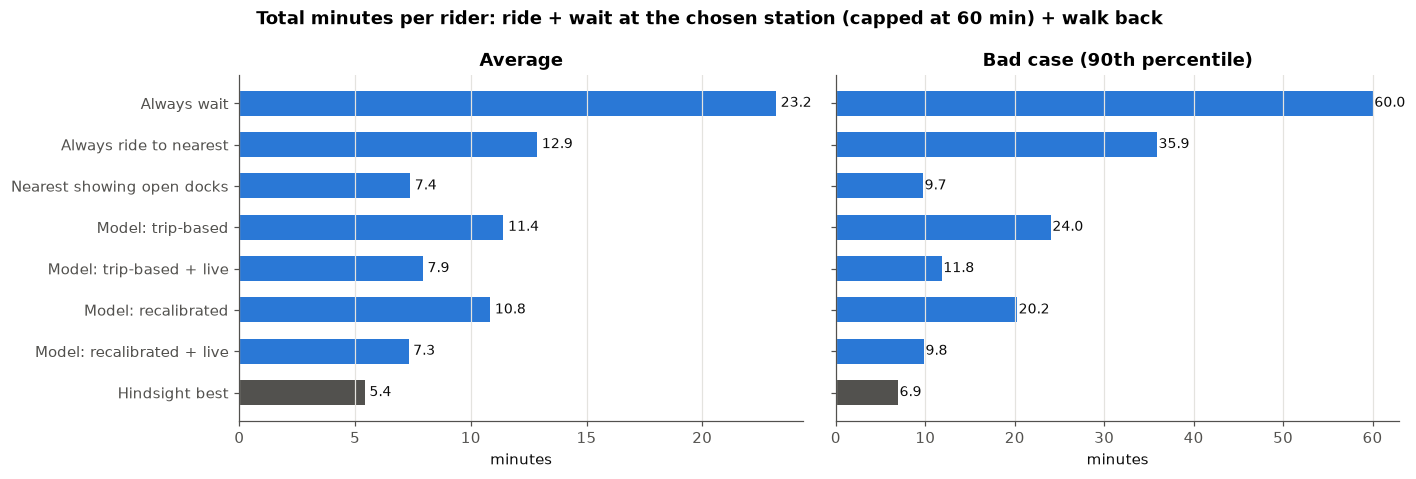

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
order = decision_summary.index[::-1]
for ax, (metric, title) in zip(axes, [("mean (min)", "Average"), ("90th pct (min)", "Bad case (90th percentile)")]):
    values = decision_summary.loc[order, metric]
    colors = [INK_SECONDARY if rule == "Hindsight best" else SERIES_COLORS[0] for rule in order]
    ax.barh(order, values, color=colors, height=0.6)
    for y_pos, value in enumerate(values):
        ax.text(value + 0.2, y_pos, f"{value:.1f}", va="center", color=INK, fontsize=9)
    ax.set_title(title)
    ax.set_xlabel("minutes")
    ax.grid(axis="y", visible=False)
fig.suptitle(f"Total minutes per rider: ride + wait at the chosen station (capped at {MAX_WAIT_MIN} min) + walk back",
             fontweight="bold")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/decision_rules_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [57]:
# Does the best rule depend on the time of day? Rider-weighted mean minutes (waits capped at 60) per rule and period
rider_w = replay.rider_weight
period_weight = rider_w.groupby(replay.period, observed=True).sum()
by_period = replay[POLICIES].mul(rider_w, axis=0).groupby(replay.period, observed=True).sum().div(period_weight, axis=0)
print("share of riders in each period: " + ", ".join(f"{p} {s:.0%}" for p, s in (period_weight / period_weight.sum()).items()))
print(f"Mean minutes per rider (waits capped at {MAX_WAIT_MIN}), by time of day:")
by_period.T.round(1)

share of riders in each period: Night 0-7h 7%, AM peak 7-10h 13%, Midday 10-16h 33%, PM peak 16-20h 28%, Evening 20-24h 19%
Mean minutes per rider (waits capped at 60), by time of day:


period,Night 0-7h,AM peak 7-10h,Midday 10-16h,PM peak 16-20h,Evening 20-24h
Always wait,43.3,23.8,19.8,18.9,27.2
Always ride to nearest,20.9,11.8,12.0,11.1,14.5
Nearest showing open docks,8.3,7.3,7.3,7.1,7.6
Model: trip-based,15.3,11.2,10.8,10.7,12.1
Model: trip-based + live,8.2,8.5,7.7,8.0,7.7
Model: recalibrated,15.3,10.6,10.3,9.8,11.7
Model: recalibrated + live,8.3,7.3,7.2,7.0,7.5
Hindsight best,7.1,5.4,5.2,5.1,5.7


**One decision, worked through.** A replayed moment where the recalibrated model with live data chose to ride on: what it saw, and what really happened.

In [58]:
detail = {name: np.concatenate([d[name] for d in replay_details]) for name in replay_details[0]}
moved = np.flatnonzero(replay["moved: Model: recalibrated + live"].to_numpy() & (detail["exists"].sum(axis=1) >= 3))
if len(moved) == 0:
    print("no replayed moment where the model chose to ride on")
else:
    i = moved[0]
    when = YEAR_START + pd.Timedelta(minutes=float(replay.t_min.iloc[i]))
    print(f"Full station: {stations[replay.station.iloc[i]]}   at {when:%a %b %d %H:%M}")
    ok = detail["exists"][i]
    example = pd.DataFrame({
        "option": ["stay (full)"] + [f"ride to {stations[s]}" for s in detail["options"][i][ok][1:]],
        "distance (m)": detail["dist"][i][ok].round(0),
        "shows open dock now": detail["open_now"][i][ok],
        "ride + walk (min)": (detail["ride_min"][i] + detail["walk_min"][i])[ok].round(1),
        "model: expected total (min)": detail["expected_recal_live"][i][ok].round(1),
        "actual total (min)": (detail["ride_min"][i] + detail["walk_min"][i] + detail["real_wait"][i])[ok].round(1),
    })
    display(example)

Full station: Bank St & Hudson St   at Sat Jan 27 05:54


,option,distance (m),shows open dock now,ride + walk (min),model: expected total (min),actual total (min)
0,stay (full),0.0,False,0.0,51.0,36.0
1,ride to W 12 St & Hudson St,122.0,True,4.0,4.0,4.0
2,ride to Perry St & Bleecker St,173.0,False,4.8,55.8,52.8
3,ride to Greenwich St & Perry St,185.0,False,5.0,54.7,51.0
4,ride to Bank St & Washington St,207.0,True,5.4,5.4,5.4
5,ride to Gansevoort St & Hudson St,327.0,True,9.3,9.3,9.3


## 10. Summary

In [59]:
check1_10 = trip_scores[trip_scores["window (min)"] == 10].set_index("model")
check2_10 = check2_all[check2_all["window (min)"] == 10].set_index("model")

print("Check 1, held-out trips, 10-minute window (Brier, lower is better):")
for model, row in check1_10.iterrows():
    print(f"  {model:<32} {row['Brier']:.4f}")
print("Check 2, real full stations, 10-minute window:")
for model, row in check2_10.iterrows():
    print(f"  {model:<30} predicted {row['avg predicted']:.1%} opened, actually {row['actually happened']:.1%}  (Brier {row['Brier']:.3f})")
print(f"Recalibration: a = {a:+.2f}, b = {b:.2f}, c = {c:+.2f}; "
      f"without elapsed time: a = {recal_params_no_live[0]:+.2f}, b = {recal_params_no_live[1]:.2f}")
print(f"Decision replay: {len(replay):,} real full-station moments, per rider, waits capped at {MAX_WAIT_MIN} minutes:")
print(decision_summary[["mean (min)", "90th pct (min)", f"% still waiting after {MAX_WAIT_MIN} min at chosen station", "% rode on"]].round(1).to_string())

Check 1, held-out trips, 10-minute window (Brier, lower is better):
  1. Station average               0.1440
  2. Time of day                   0.1146
  3. Time of day + weather/season  0.1086
Check 2, real full stations, 10-minute window:
  trip-based                     predicted 16.8% opened, actually 14.4%  (Brier 0.097)
  recalibrated                   predicted 14.4% opened, actually 14.4%  (Brier 0.091)
  recalibrated, no elapsed time  predicted 15.6% opened, actually 14.4%  (Brier 0.093)
Recalibration: a = -0.53, b = 0.61, c = -0.22; without elapsed time: a = -0.77, b = 0.77
Decision replay: 47,894 real full-station moments, per rider, waits capped at 60 minutes:
                            mean (min)  90th pct (min)  % still waiting after 60 min at chosen station  % rode on
rule                                                                                                             
Always wait                       23.2            60.0                                     

### Results in words
Numbers are from the run saved in this notebook (full 2024 data, `SEED = 42`). Decision results are total minutes per rider (ride + wait at the chosen station + walk back), with the **wait capped at 60 minutes**.

**1. Are the probabilities right?** On held-out trips, each model ingredient lowers the 10-minute Brier score (0.144 → 0.115 → 0.109), although the full model predicts more departures than happen (23.2% vs. 20.5% at 10 minutes; partly because some random moments fall when a station is empty). At real full stations the trip-based model is too optimistic: it gives a 16.8% chance that a dock opens within 10 minutes, and that happened 14.4% of the time. The recalibration fitted on days 15–21 matches that average (14.4%; Brier 0.097 → 0.091), and the version without elapsed time, used when there's no live data, gets 15.6% (Brier 0.093). Matching averages don't make every individual probability right; the reliability and survival plots show where the models still miss (for example, evenings).

**2. Does the model improve the decision?** Replaying 47,894 moments when every candidate station was working:
- **Without live data**, the recalibrated model beats the simple rules tested: 10.8 minutes on average, against 12.9 for always riding to the nearest station and 23.2 for always waiting, with a 90th percentile of 20.2 vs. 35.9 minutes. It's ahead of riding to the nearest station in every period of the day, by 1.2 minutes (AM peak) to 5.6 minutes (night).
- **With live data**, riding to the nearest station showing an open dock averages 7.4 minutes and the recalibrated model 7.3, effectively a tie (90th percentile 9.7 vs. 9.8). The uncalibrated version does worse than that simple rule (7.9 minutes; 90th percentile 11.8), mostly between 7 am and 8 pm: it expects docks at busy stations to open faster than they do, so it waits when it should ride on.
- In hindsight the best choice was to wait for about a quarter of riders, because a dock happened to open within minutes; the nearest-open-dock rule and the recalibrated model with live data ride on 96–98% of the time, so they rarely wait at those moments.
- Always waiting leaves 19% of riders still waiting after an hour.

**In short:** without live information, the model does better than simple rules; with live information, a one-line rule does as well, and the uncalibrated model does worse than it.

### Limitations
- **Which moments.** The replay keeps only moments when every candidate station (the full station and its up to 5 nearest neighbors within 500 m) was in service and reporting for the whole hour (48k of 60k sampled), and none from the last hour of each month, whose following hour isn't in the data. It describes those conditions.
- **Measurement.** Snapshots are 2 minutes apart, so waits are measured to the 2-minute step and docks that open and refill between snapshots are missed. Reports older than 10 minutes, or without a report time, count as missing, including a feed freeze of about 2.3 days in July.
- **Simplified riders.** One rider's choice doesn't affect anyone else, riders who ride on go directly without re-checking the app, and travel times use straight-line distance × 1.3 at constant speeds. Other radii and speeds weren't tested.
- **Information.** The models use the weather observed over the next hour, a stand-in for a short-term forecast. Station locations are medians over the whole year's trips.
- **Model.** One weather effect for the whole city. Competition for docks and rebalancing are captured only through the recalibration, whose elapsed-time term mixes time already full with differences between stations. Rider weights come from trip arrivals, which undercount demand at often-full stations.
- **Uncertainty.** These are point estimates from one sample of moments in one year, without confidence intervals; differences of a few tenths of a minute should be read as ties.

### Possible extensions
- Sensitivity analysis on the radius, K and travel speeds, with bootstrap intervals.
- Model competition directly with arrival rates, and let the recalibration vary by time of day.
- Use forecast rather than observed weather, and test on later data (2025 trips and the live feed).
- The empty-station case (waiting for a bike), and recommending a station before arriving.